# 5. Entrenamiento y comparación de los modelos — V2 (100 % de ENTRENAMIENTO)

> **Versión 2.** Misma metodología de la versión 1 (`5_Entrenamiento_Modelos.ipynb`), pero las redes se entrenan con **todos los usuarios de ENTRENAMIENTO** (≈ 76 millones de registros en lugar del 25 %, ≈ 19 millones). Todas las salidas van a `Superintendencia/V2/` y **no sobrescriben** los resultados de la versión 1, que solo se leen.
>
> | Cambio respecto a la versión 1 | Motivo |
> |---|---|
> | `FRAC_USUARIOS_TRAIN = 1.0` | Entrenar con el 100 % de ENTRENAMIENTO. |
> | Carga **por bloques** de usuarios (una sola lectura del conjunto) y tensores compactos (`uint8`/`int8`, secuencia como valor + máscara, mes cíclico calculado por lote) | Un único DataFrame de 76 millones de filas no cabe en 51 GB de RAM junto a los tensores; así el pico queda en ≈ 25–30 GB. |
> | Preprocesamiento (medianas, IQR, transformaciones) ajustado con el 100 % de ENTRENAMIENTO | Antes se ajustaba con la muestra del 25 %. |
> | `FRAC_MONITOR = 0.05` | Con el 100 %, el 5 % de los usuarios (≈ 3,8 millones de registros) basta para la parada temprana y deja el 95 % para ajustar pesos. |
> | `PACIENCIA = 2` | En la versión 1 las tres redes tuvieron su mejor época en la 1.ª; cada época ahora es ≈ 4 veces más larga. |
> | `REUTILIZAR_BUSQUEDA_V1 = True` y `FRAC_AJUSTE_HP = 0.075` | Se reutilizan las 24 pruebas de hiperparámetros de la versión 1 (mismas configuraciones), de modo que la diferencia con la V1 se deba solo al tamaño de los datos. Si se fija en `False`, la búsqueda se repite con un subconjunto de tamaño similar al de la V1. |
> | Generador de lotes con `WORKERS_LOTES` hilos | Prepara lotes en paralelo mientras la GPU entrena. |

**Entradas:**
- `dataset_modelo_prep` (109.020.828 registros, 30 columnas; `2_Preparación de los datos.ipynb`).
- Catálogos `catalogo_clusters_transformador` y `catalogo_clusters_circuito` (`3_Modelado_Categoricas.ipynb`).
- Modelos compilados sin entrenar y `config_entradas.json` (`4_Propuesta_Arquitecturas.ipynb`).

**Objetivo de este cuaderno:** optimizar los hiperparámetros y entrenar las tres arquitecturas propuestas, compararlas entre sí en la partición de **prueba** y evaluar el modelo seleccionado frente a la línea base semestral (`BENCH_KWH_DIA`) en la partición de **validación**, con MAE, RMSE y R².

| Sección | Contenido |
|---|---|
| 0 | Principios y partición 70-15-15 |
| 1 | Librerías, parámetros y rutas en Google Drive |
| 2 | Carga del conjunto, de los catálogos y de los modelos propuestos |
| 3 | Verificación de la partición determinista |
| 4 | Funciones de carga por partición, unión con catálogos y secuencia de consumo |
| 5 | Entrenamiento: descriptivas, tipos de dato y ajuste del preprocesamiento |
| 6 | Construcción de tensores, generador de lotes y carga de PRUEBA |
| 7 | **Optimización de hiperparámetros** (búsqueda aleatoria evaluada en PRUEBA) |
| 8 | Entrenamiento final de las tres arquitecturas con sus mejores hiperparámetros |
| 9 | Comparación de los modelos en PRUEBA (15 %) |
| 10 | Validación del modelo seleccionado frente a la línea base (15 %) |
| 11 | Resumen y exportación |

> El modelo de referencia de árboles (**LightGBM**) está en `6_Modelo_LightGBM.ipynb`, que corre en CPU y puede ejecutarse en paralelo; al final se compara con las redes de este cuaderno.

**Salidas en Google Drive (`Superintendencia/V2/`):**
- `V2/Modelos_5_Entrenamiento/`: modelos entrenados (`*_entrenado.keras`), *checkpoints*, `preprocesamiento.json` y `mejores_hiperparametros.json`.
- `V2/Resultados_5_Entrenamiento_Modelos/`: historias de entrenamiento, tablas de métricas y resumen.
- `V2/Figuras_5_Entrenamiento_Modelos/`: curvas de aprendizaje y gráficas de evaluación.

> **Entorno:** Colab con GPU T4 y RAM alta (51 GB). La carga por bloques usa además el disco local de Colab (≈ 10–15 GB temporales).

## 0. Principios y partición 70-15-15

### 0.1 Partición

Se reutiliza la **misma asignación determinista por usuario** del cuaderno 3: los primeros cuatro dígitos hexadecimales de `NIU_USUARIO` (base 65.536). Los catálogos de *clustering* se calcularon solo con el 70 % de entrenamiento, así que ninguna de las otras dos particiones aporta información a las entradas.

| Partición | Rango hexadecimal | % de usuarios | Uso en este cuaderno | Nombre en el cuaderno 3 |
|---|---|---|---|---|
| **ENTRENAMIENTO** | `[0, 45.875)` | 70 % | Ajuste de pesos y del preprocesamiento (escalado, transformaciones, vocabularios) | `TRAIN` |
| **PRUEBA** | `[45.875, 55.706)` | 15 % | **Optimización de hiperparámetros, comparación de las tres arquitecturas** y selección del modelo | `VAL` |
| **VALIDACIÓN** | `[55.706, 65.536)` | 15 % | **Evaluación final del modelo seleccionado frente a la línea base** | `TEST` |

Los nombres siguen el documento (§2.3): «los hiperparámetros se ajustan según el mejor desempeño sobre los datos de prueba. Los datos de validación se reservan para la evaluación final».

> **Nota de terminología.** En la literatura de aprendizaje automático en inglés el uso suele ser el inverso: *validation set* para ajustar hiperparámetros y *test set* para la evaluación final. Aquí **PRUEBA ≈ *validation set*** y **VALIDACIÓN ≈ *test set* (*hold-out*)**. Esta equivalencia debe aclararse también en el documento de la tesis (capítulos de metodología y resultados).

### 0.2 Principios

1. **Sin fuga de información.** Todo lo que se estima con datos (transformaciones, medianas, IQR, vocabularios, pesos de la red) se ajusta solo con ENTRENAMIENTO. PRUEBA solo se usa para **elegir** (hiperparámetros y arquitectura), nunca para ajustar pesos. VALIDACIÓN se abre una sola vez, al final, para el modelo ya seleccionado; por eso es la única estimación no sesgada del desempeño.
2. **Parada temprana dentro de ENTRENAMIENTO.** Se separa un subconjunto de monitoreo (`FRAC_MONITOR` de los usuarios, por el mismo hash) para `EarlyStopping` y `ReduceLROnPlateau`, de modo que el número de épocas no se elige con PRUEBA.
3. **Independencia por usuario.** La partición es por usuario, por lo que todos los meses de un usuario quedan en la misma partición. Las comparaciones estadísticas en VALIDACIÓN usan *bootstrap* por usuario.
4. **Mismo filtro para modelo y línea base.** La comparación con `BENCH_KWH_DIA` se hace en el subconjunto comparable del documento (Tabla 3.3): `BENCH_VALIDO == 1`, consumo real y línea base ≤ 100 kWh/día.
5. **Todos los usuarios de ENTRENAMIENTO.** En esta versión `FRAC_USUARIOS_TRAIN = 1.0`: las redes se ajustan con el 95 % de los usuarios de ENTRENAMIENTO y el 5 % restante (por el mismo hash) solo se usa para la parada temprana.

### 0.3 Reanudación tras una desconexión de Colab

Todo avance se guarda en Drive en cuanto se produce. Si Colab se desconecta, basta con **volver a ejecutar el cuaderno desde el principio**: cada etapa detecta lo que ya está hecho y continúa desde ahí.

| Etapa | Qué se guarda en Drive | Qué pasa al volver a ejecutar |
|---|---|---|
| 3. Verificación de la partición | `00_resumen_particion.csv` | Se lee la tabla; no se recalcula. |
| 5. Preprocesamiento | `preprocesamiento.json` y `01_descriptivas_y_transformaciones.csv` | Si las tres redes ya terminaron, se leen y **no se vuelve a cargar ENTRENAMIENTO**. |
| 7. Búsqueda de hiperparámetros | Una fila por prueba en `09_busqueda_hiperparametros.csv` | Se omiten las pruebas completadas. Si cambiaron los parámetros de la búsqueda, se detiene con un aviso. |
| 8. Entrenamiento final | Por época: modelo completo con estado del optimizador (`*_ultimo.keras`), mejor modelo (`*_mejor.keras`) e historia (`historia_*.csv`) | Las redes terminadas (`*_entrenado.keras`) se omiten. La que estaba a medias **continúa desde la última época completa**, con la tasa de aprendizaje y los contadores de parada temprana restaurados. |
| 9 y 10. Predicciones en PRUEBA y VALIDACIÓN | `cache_predicciones/*.npz` | Se reutilizan si coinciden el modelo y los registros (firma de verificación). |

Lo único que se repite en cada sesión es la copia local del conjunto, el reparto en bloques y la construcción de los tensores de las particiones que se necesiten, porque el disco local de Colab se borra al desconectar.

> Para empezar de cero (por ejemplo, tras cambiar parámetros) se fija `FORZAR_REINICIO = True`: se ignoran los avances guardados y se sobrescriben.

## 1. Librerías, parámetros y rutas en Google Drive

In [1]:
import os
import gc
import json
import math
import time
import glob
import shutil
import hashlib
import warnings
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import dask.dataframe as dd
import matplotlib.pyplot as plt
import keras
from google.colab import drive

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
pd.options.display.float_format = '{:,.4f}'.format
PALETA = ['#2C3E50', '#2980B9', '#27AE60', '#E67E22', '#C0392B', '#8E44AD']

print(f'Keras {keras.__version__} | backend: {keras.backend.backend()}')
try:
    import tensorflow as tf
    print('GPU disponibles:', tf.config.list_physical_devices('GPU'))
except ImportError:
    pass
try:
    import psutil
    print(f'RAM total: {psutil.virtual_memory().total / 1024 ** 3:.1f} GB | '
          f'disco libre: {shutil.disk_usage(".").free / 1024 ** 3:.1f} GB')
except ImportError:
    pass

Keras 3.13.2 | backend: tensorflow
GPU disponibles: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
RAM total: 51.0 GB | disco libre: 235.6 GB


In [2]:
# Rutas en Google Drive
drive.mount('/content/drive')
DRIVE_RAIZ        = '/content/drive/MyDrive/Superintendencia'
DRIVE_ORIGEN      = os.path.join(DRIVE_RAIZ, 'dataset_modelo_prep')
LOCAL_ORIGEN      = './dataset_modelo_prep'
DIR_CATALOGOS     = os.path.join(DRIVE_RAIZ, 'Catalogos_Categorias')
DIR_MODELOS_PROP  = os.path.join(DRIVE_RAIZ, 'Modelos_4_Propuesta_Arquitecturas')
# Salidas de esta versión: todo bajo Superintendencia/V2 (no se toca nada de la versión 1)
DRIVE_SALIDA      = os.path.join(DRIVE_RAIZ, 'V2')
DIR_MODELOS_ENT   = os.path.join(DRIVE_SALIDA, 'Modelos_5_Entrenamiento')
DIR_CHECKPOINTS   = os.path.join(DIR_MODELOS_ENT, 'checkpoints')
DIR_RESULTADOS    = os.path.join(DRIVE_SALIDA, 'Resultados_5_Entrenamiento_Modelos')
DIR_FIGURAS       = os.path.join(DRIVE_SALIDA, 'Figuras_5_Entrenamiento_Modelos')
DIR_CACHE         = os.path.join(DIR_RESULTADOS, 'cache_predicciones')
# Solo lectura: búsqueda de hiperparámetros de la versión 1
RUTA_BUSQUEDA_HP_V1 = os.path.join(DRIVE_RAIZ, 'Resultados_5_Entrenamiento_Modelos', '09_busqueda_hiperparametros.csv')
# Disco local de Colab (temporal): bloques de usuarios y arreglos intermedios
LOCAL_BLOQUES     = './bloques_v2'
LOCAL_TENSORES    = './tensores_v2'
for directorio in (DIR_MODELOS_ENT, DIR_CHECKPOINTS, DIR_RESULTADOS, DIR_FIGURAS, DIR_CACHE):
    os.makedirs(directorio, exist_ok=True)

RUTA_PREP          = os.path.join(DIR_MODELOS_ENT, 'preprocesamiento.json')
RUTA_MEJORES_HP    = os.path.join(DIR_MODELOS_ENT, 'mejores_hiperparametros.json')
RUTA_DIAGNOSTICO   = os.path.join(DIR_RESULTADOS, '01_descriptivas_y_transformaciones.csv')
RUTA_PARTICION     = os.path.join(DIR_RESULTADOS, '00_resumen_particion.csv')
RUTA_BUSQUEDA_HP   = os.path.join(DIR_RESULTADOS, '09_busqueda_hiperparametros.csv')

# Reanudación: False = continuar con los avances guardados en Drive; True = ignorarlos y empezar de cero
FORZAR_REINICIO = False

SEMILLA = 42
keras.utils.set_random_seed(SEMILLA)

# 1. Partición 70-15-15 por hash de NIU_USUARIO (idéntica al cuaderno 3)
HEX_MAX            = 65536
UMBRAL_HEX_TRAIN   = int(round(0.70 * HEX_MAX))   # 45.875
UMBRAL_HEX_PRUEBA  = int(round(0.85 * HEX_MAX))   # 55.706

# 2. Fracción de usuarios usada en cada partición (1.0 = todos)
FRAC_USUARIOS_TRAIN  = 1.00   # V2: todos los usuarios de ENTRENAMIENTO
FRAC_MONITOR         = 0.05   # parte de ENTRENAMIENTO reservada para EarlyStopping (no se usa para ajustar pesos)
FRAC_USUARIOS_PRUEBA = 1.00
FRAC_USUARIOS_VALID  = 1.00

# 2b. Carga por bloques de usuarios (V2) y generador de lotes
N_BLOQUES      = {'ENTRENAMIENTO': 8, 'PRUEBA': 2, 'VALIDACION': 2}   # ≈ 9,5 millones de registros por bloque de entrenamiento
WORKERS_LOTES  = 4            # hilos que preparan lotes en paralelo
MAX_COLA_LOTES = 16           # lotes preparados por adelantado

# 3. Entrenamiento final
TAMANO_LOTE_PRED   = 32768
MAX_EPOCAS         = 20
PACIENCIA          = 2        # épocas sin mejora en el monitoreo antes de detener (V1: mejor época = 1 en las tres redes)

# 4. Optimización de hiperparámetros (búsqueda aleatoria, sección 7)
REUTILIZAR_BUSQUEDA_V1 = True # copia a V2 las pruebas ya hechas en la versión 1 (mismas configuraciones)
N_PRUEBAS_HP       = 8        # configuraciones por arquitectura (la primera es siempre la propuesta del cuaderno 4)
FRAC_AJUSTE_HP     = 0.075    # fracción de los usuarios de ajuste por prueba (≈ 5 millones de registros, como en la V1)
FRAC_PRUEBA_HP     = 0.30     # fracción de los usuarios de PRUEBA usada para puntuar cada prueba
MAX_EPOCAS_HP      = 6
PACIENCIA_HP       = 2
HP_PROPUESTA = {              # valores del cuaderno 4
    'tasa_aprendizaje': 1e-3, 'tamano_lote': 4096, 'escala_dropout': 1.0,
    'delta_huber': 1.0, 'peso_prob_cero': 0.3,
}
ESPACIO_HP = {
    'tasa_aprendizaje': (1e-4, 3e-3),       # log-uniforme
    'tamano_lote': [2048, 4096, 8192],
    'escala_dropout': [0.5, 1.0, 1.5],      # multiplica las tasas de Dropout de la propuesta (máx. 0,6)
    'delta_huber': [0.5, 1.0, 2.0],
    'peso_prob_cero': [0.1, 0.3, 0.5],      # solo arquitectura 3
}

# 5. Preprocesamiento
UMBRAL_ASIMETRIA_G1   = 1.0       # mismo criterio que el cuaderno 3 para aplicar log(1 + x)
CLIP_Z                = 10.0      # límite de |z| tras el escalado robusto
MUESTRA_DIAGNOSTICO   = 2_000_000 # registros para descriptivas y asimetría
ANIO_BASE_MES         = 2015      # origen del índice mensual de la secuencia

# 6. Evaluación
LIMITE_COMPARABLE_KWH = 100.0     # Tabla 3.3 del documento
CRITERIO_SELECCION    = 'MAE'     # métrica para elegir el modelo en PRUEBA (todos los registros)
N_BOOTSTRAP           = 1000
UMBRALES_PROB_CERO    = [0.5, 0.6, 0.7, 0.8, 0.9]   # regla «predecir 0 si prob_cero >= umbral» (arq. 3, sección 9)
SUFIJO_UMBRAL         = '+umbral_cero'
GUARDAR_PREDICCIONES_VALID = True


def rango_hex(inicio, fin, fraccion):
    return inicio, inicio + int(round((fin - inicio) * fraccion))

RANGOS = {
    'ENTRENAMIENTO': rango_hex(0, UMBRAL_HEX_TRAIN, FRAC_USUARIOS_TRAIN),
    'PRUEBA':        rango_hex(UMBRAL_HEX_TRAIN, UMBRAL_HEX_PRUEBA, FRAC_USUARIOS_PRUEBA),
    'VALIDACION':    rango_hex(UMBRAL_HEX_PRUEBA, HEX_MAX, FRAC_USUARIOS_VALID),
}
# Monitoreo: el último FRAC_MONITOR del rango de entrenamiento usado
HEX_INICIO_MONITOR = RANGOS['ENTRENAMIENTO'][1] - int(round(RANGOS['ENTRENAMIENTO'][1] * FRAC_MONITOR))

pd.DataFrame(RANGOS, index=['hex_desde', 'hex_hasta (excl.)']).T.assign(
    pct_del_total=lambda d: (d['hex_hasta (excl.)'] - d['hex_desde']) / HEX_MAX * 100
)

Mounted at /content/drive


,hex_desde,hex_hasta (excl.),pct_del_total
ENTRENAMIENTO,0,45875,69.9997
PRUEBA,45875,55706,15.0009
VALIDACION,55706,65536,14.9994


In [3]:
def guardar_figura(fig, nombre):
    fig.savefig(os.path.join(DIR_FIGURAS, f'{nombre}.png'), dpi=150, bbox_inches='tight')


def guardar_tabla(df, nombre):
    df.to_csv(os.path.join(DIR_RESULTADOS, f'{nombre}.csv'), encoding='utf-8')


def metricas_regresion(y, y_hat):
    y = np.asarray(y, dtype='float64')
    y_hat = np.asarray(y_hat, dtype='float64')
    ok = np.isfinite(y) & np.isfinite(y_hat)
    y, y_hat = y[ok], y_hat[ok]
    e = y_hat - y
    ss_tot = ((y - y.mean()) ** 2).sum()
    return {
        'n': int(ok.sum()),
        'MAE': np.abs(e).mean(),
        'RMSE': np.sqrt((e ** 2).mean()),
        'R2': 1.0 - (e ** 2).sum() / ss_tot if ss_tot > 0 else np.nan,
        'Sesgo': e.mean(),
    }


def auc_roc(etiqueta, puntaje):
    # AUC = estadístico U de Mann-Whitney normalizado
    etiqueta = np.asarray(etiqueta).astype(bool)
    n1, n0 = etiqueta.sum(), (~etiqueta).sum()
    if n1 == 0 or n0 == 0:
        return np.nan
    rangos = pd.Series(puntaje).rank(method='average').to_numpy()
    return (rangos[etiqueta].sum() - n1 * (n1 + 1) / 2) / (n1 * n0)

## 2. Carga del conjunto, de los catálogos y de los modelos propuestos

In [4]:
# 2.1 Copia local del conjunto particionado por ANIO (lectura más rápida que desde Drive)
archivos_drive = sorted(glob.glob(os.path.join(DRIVE_ORIGEN, '**', '*.parquet'), recursive=True))
print(f'Archivos parquet encontrados en Drive: {len(archivos_drive):,}')

def _copiar_preservando_particion(ruta_origen):
    rel = os.path.relpath(ruta_origen, DRIVE_ORIGEN)
    ruta_destino = os.path.join(LOCAL_ORIGEN, rel)
    os.makedirs(os.path.dirname(ruta_destino), exist_ok=True)
    if not os.path.exists(ruta_destino):
        shutil.copy2(ruta_origen, ruta_destino)

with ThreadPoolExecutor(max_workers=8) as ex:
    list(ex.map(_copiar_preservando_particion, archivos_drive))
print('Copia local completada en:', LOCAL_ORIGEN)

Archivos parquet encontrados en Drive: 734
Copia local completada en: ./dataset_modelo_prep


In [5]:
# 2.2 Contrato de entradas del cuaderno 4
with open(os.path.join(DIR_MODELOS_PROP, 'config_entradas.json'), encoding='utf-8') as fh:
    config = json.load(fh)

NUM_TABULAR            = config['num_tabular']
NUM_CON_NULOS          = config['num_con_nulos']
BANDERAS_NULO          = config['banderas_nulo']
CTX_TRAFO              = config['ctx_trafo']
CTX_CIRC               = config['ctx_circ']
CTX                    = CTX_TRAFO + CTX_CIRC
CATEGORICAS            = config['categoricas']          # {nombre: cardinalidad}, en orden
N_MESES_SECUENCIA      = config['arq3_n_meses_secuencia']
NUM_ESTATICAS_SEQ      = config['arq3_num_estaticas']
BANDERAS_ESTATICAS_SEQ = config['arq3_banderas_estaticas']
NOMBRES_MODELOS        = list(config['archivos_modelo'])

IDX_ESTATICAS_SEQ = [NUM_TABULAR.index(c) for c in NUM_ESTATICAS_SEQ]
IDX_BANDERAS_SEQ  = [BANDERAS_NULO.index(c) for c in BANDERAS_ESTATICAS_SEQ]

print('Modelos a entrenar:', NOMBRES_MODELOS)
print(f'Numéricas: {len(NUM_TABULAR)} | banderas: {len(BANDERAS_NULO)} | contexto: {len(CTX)} | categóricas: {len(CATEGORICAS)}')

Modelos a entrenar: ['arq1_mlp_sequential', 'arq2_embeddings_wide_deep', 'arq3_conv1d_lstm_hurdle']
Numéricas: 17 | banderas: 11 | contexto: 14 | categóricas: 5


In [6]:
# 2.3 Catálogos del cuaderno 3 -> tablas de búsqueda por transformador y por circuito
def limpiar_circuito(serie):
    # Misma limpieza que el cuaderno 3 (sección 4.1)
    return serie.astype(str).str.strip().replace({'': 'SIN_CIRCUITO'})

cat_trafo = pd.read_parquet(os.path.join(DIR_CATALOGOS, 'catalogo_clusters_transformador.parquet'))
cat_circ  = pd.read_parquet(os.path.join(DIR_CATALOGOS, 'catalogo_clusters_circuito.parquet'))

tabla_trafo = pd.DataFrame(index=pd.Index(cat_trafo['COD_TRANSFORMADOR'].astype(str), name='COD_TRANSFORMADOR'))
for col in CTX_TRAFO:
    origen = col.replace('TRAFO_', '', 1)
    if origen == 'LOG_N_USUARIOS':
        tabla_trafo[col] = np.log1p(cat_trafo['N_USUARIOS'].to_numpy(dtype='float64'))
    else:
        tabla_trafo[col] = cat_trafo[origen].to_numpy(dtype='float64')
tabla_trafo['CLUSTER_TRANSFORMADOR'] = cat_trafo['CLUSTER_TRANSFORMADOR'].astype(str).to_numpy()
tabla_trafo['CLUSTER_CIRCUITO'] = cat_trafo['CLUSTER_CIRCUITO'].astype(str).to_numpy()
tabla_trafo = tabla_trafo.loc[~tabla_trafo.index.duplicated(keep='first')]

clave_circ = limpiar_circuito(cat_circ['COD_CIRCUITO_LINEA'])
tabla_circ = pd.DataFrame(index=pd.Index(clave_circ, name='COD_CIRCUITO_CLEAN'))
for col in CTX_CIRC:
    tabla_circ[col] = cat_circ[col.replace('CIRC_', '', 1)].to_numpy(dtype='float64')
tabla_circ = tabla_circ.loc[~tabla_circ.index.duplicated(keep='first')]

# Vocabularios de los clústeres (no dependen del objetivo); índice 0 = categoría no vista
VOCAB_CLUSTER_TRAFO = sorted(tabla_trafo['CLUSTER_TRANSFORMADOR'].unique())
VOCAB_CLUSTER_CIRC  = sorted(tabla_trafo['CLUSTER_CIRCUITO'].unique())
assert len(VOCAB_CLUSTER_TRAFO) <= CATEGORICAS['CLUSTER_TRANSFORMADOR'], 'Hay más clústeres de transformador que los previstos en el cuaderno 4'
assert len(VOCAB_CLUSTER_CIRC) <= CATEGORICAS['CLUSTER_CIRCUITO'], 'Hay más clústeres de circuito que los previstos en el cuaderno 4'

print(f'Transformadores en catálogo: {len(tabla_trafo):,} | circuitos en catálogo: {len(tabla_circ):,}')
print(f'CLUSTER_TRANSFORMADOR ({len(VOCAB_CLUSTER_TRAFO)}): {VOCAB_CLUSTER_TRAFO}')
print(f'CLUSTER_CIRCUITO ({len(VOCAB_CLUSTER_CIRC)}): {VOCAB_CLUSTER_CIRC}')

Transformadores en catálogo: 37,346 | circuitos en catálogo: 1,063
CLUSTER_TRANSFORMADOR (15): ['T01', 'T02', 'T03', 'T04', 'T05', 'T06', 'T07', 'T08', 'T09', 'T10', 'T11', 'T12', 'T13', 'T14', 'T15']
CLUSTER_CIRCUITO (21): ['C00_SIN_CIRC_E1', 'C00_SIN_CIRC_E2', 'C00_SIN_CIRC_E3', 'C00_SIN_CIRC_E4', 'C00_SIN_CIRC_E5', 'C00_SIN_CIRC_E6', 'C01', 'C02', 'C03', 'C04', 'C05', 'C06', 'C07', 'C08', 'C09', 'C10', 'C11', 'C12', 'C13', 'C14', 'C15']


## 3. Verificación de la partición determinista

El filtro de cada partición compara el prefijo hexadecimal de `NIU_USUARIO` como texto (rápido en Dask). Esto equivale a la comparación numérica solo si todos los prefijos son hexadecimales válidos de cuatro caracteres; se verifica aquí sobre el 100 % del conjunto.

In [7]:
if os.path.exists(RUTA_PARTICION) and not FORZAR_REINICIO:
    print('Verificación ya realizada en una sesión anterior: se lee desde Drive.')
    resumen_particion = pd.read_csv(RUTA_PARTICION, index_col=0)
else:
    prefijos = dd.read_parquet(LOCAL_ORIGEN, columns=['NIU_USUARIO'])['NIU_USUARIO'].str.slice(0, 4).str.lower()
    conteo_prefijos = prefijos.value_counts().compute()

    validos = conteo_prefijos.index.str.fullmatch(r'[0-9a-f]{4}')
    assert validos.all(), f'Prefijos no hexadecimales: {list(conteo_prefijos.index[~validos][:10])}'

    hex_prefijo = np.array([int(p, 16) for p in conteo_prefijos.index])
    registros = conteo_prefijos.to_numpy()
    asignacion = np.select([hex_prefijo < UMBRAL_HEX_TRAIN, hex_prefijo < UMBRAL_HEX_PRUEBA],
                           ['ENTRENAMIENTO', 'PRUEBA'], default='VALIDACION')

    resumen_particion = pd.DataFrame({'PARTICION': asignacion, 'Registros': registros}).groupby('PARTICION').sum()
    resumen_particion['% Registros'] = resumen_particion['Registros'] / resumen_particion['Registros'].sum() * 100
    resumen_particion['Registros usados'] = [
        int(registros[(hex_prefijo >= RANGOS[p][0]) & (hex_prefijo < RANGOS[p][1])].sum()) for p in resumen_particion.index
    ]
    resumen_particion = resumen_particion.loc[['ENTRENAMIENTO', 'PRUEBA', 'VALIDACION']]
    guardar_tabla(resumen_particion, '00_resumen_particion')
resumen_particion

,Registros,% Registros,Registros usados
PARTICION,,,
ENTRENAMIENTO,76268225,69.9575,76268225
PRUEBA,16363756,15.0098,16363756
VALIDACION,16388847,15.0328,16388847


## 4. Funciones de carga por bloques, unión con catálogos y secuencia de consumo

**Carga por bloques (V2).** Con el 100 % de ENTRENAMIENTO (≈ 76 millones de registros) no es posible tener a la vez un `DataFrame` de pandas con todas las columnas y los tensores en 51 GB de RAM. Por eso:
1. **`asegurar_bloques`** lee el conjunto **una sola vez** con Dask y reparte los registros de las particiones pedidas en bloques por **rango del hash de usuario** (`N_BLOQUES`), guardados como Parquet en el disco local de Colab. Como el corte es por usuario, todos los meses de un usuario quedan en el mismo bloque y la secuencia de 12 meses se puede construir bloque a bloque.
2. **`construir_crudo`** procesa cada bloque (lectura, unión con catálogos, secuencia), lo convierte en arreglos compactos sin transformar (`float32`, categóricas como índices `int8`, máscara de la secuencia `uint8`), los guarda en disco y al final los reúne en un único arreglo por variable. El pico de RAM es el arreglo final más un bloque.
3. El preprocesamiento (sección 5.3) se ajusta sobre esos arreglos y se aplica **en el mismo espacio de memoria** (`transformar_en_sitio`, sección 6), sin duplicarlos.

El resultado es idéntico al de la versión 1 (mismas transformaciones, mismo orden de columnas y mismas entradas a las redes); solo cambia la forma de construirlo.

- **`enriquecer`** (sin cambios respecto a la versión 1):
  1. Une el contexto continuo y los clústeres por `COD_TRANSFORMADOR` (catálogo de transformador). `CLUSTER_CIRCUITO` se toma de ese catálogo porque allí los transformadores sin circuito están separados por estrato (`C00_SIN_CIRC_E1` … `E6`).
  2. Une el contexto del circuito por `COD_CIRCUITO_LINEA` limpio (catálogo de circuito).
  3. Construye la **secuencia de los 12 meses previos** de `KWH_DIA` de cada usuario (t−12 … t−1) para la arquitectura 3. Se busca por mes calendario (no por fila), de modo que un mes sin factura queda como «no observado» y no desplaza la ventana.
  4. **Completa t−1, t−3 y t−12 con los rezagos de BigQuery** (`KWH_DIA_LAG1`, `KWH_DIA_LAG3`, `KWH_DIA_LAG12`) cuando el panel no tiene ese mes.

**Por qué el paso 4.** Los rezagos del cuaderno 2 se calcularon en BigQuery **antes** del filtro de lectura real, mientras que la secuencia se arma con el panel **ya filtrado**. Sin el paso 4, un mes con factura estimada quedaría como `OBSERVADO = 0` en la secuencia, aunque las arquitecturas 1 y 2 sí reciben su valor como rezago, y la arquitectura 3 tendría menos información. Ambas fuentes usan ventanas por mes calendario (documento, §2.3), y la función reporta el **% de coincidencia** donde las dos tienen dato para verificarlo.

> **Limitación que persiste:** los meses t−2 y t−4 a t−11 no tienen rezago individual en el conjunto (solo entran resumidos en `KWH_DIA_MM3`, `KWH_DIA_MM6` y `KWH_DIA_STD6`), así que en esas posiciones la secuencia solo tiene los meses con lectura real. Si la arquitectura 2 supera a la 3, esta diferencia de información debe mencionarse en la discusión.

In [8]:
COLS_LECTURA = [
    'PERIODO', 'NIU_USUARIO', 'KWH_DIA', 'BENCH_KWH_DIA', 'BENCH_VALIDO',
    'ESTRATO_SECTOR', 'TIPO_MEDIDOR', 'MES_CONSUMO', 'COD_TRANSFORMADOR', 'COD_CIRCUITO_LINEA',
] + NUM_TABULAR


# Tabla de conversión de caracteres hexadecimales (vectorizada, sin bucles de Python)
_HEX_LUT = np.full(256, -1, dtype=np.int32)
for _i, _c in enumerate(b'0123456789abcdef'):
    _HEX_LUT[_c] = _i
for _i, _c in enumerate(b'ABCDEF'):
    _HEX_LUT[_c] = 10 + _i


def hex_prefijo(serie):
    # Entero de los primeros 4 dígitos hexadecimales de NIU_USUARIO
    crudo = serie.str.slice(0, 4).to_numpy(dtype='S4')
    digitos = _HEX_LUT[np.frombuffer(crudo.tobytes(), dtype=np.uint8).reshape(-1, 4)]
    if (digitos < 0).any():
        raise ValueError('Hay prefijos de NIU_USUARIO que no son hexadecimales de 4 caracteres')
    return (digitos[:, 0] * 4096 + digitos[:, 1] * 256 + digitos[:, 2] * 16 + digitos[:, 3]).astype('int32')


ID_BASE_BLOQUE = {'ENTRENAMIENTO': 0, 'PRUEBA': 1000, 'VALIDACION': 2000}


def limites_bloques(nombre):
    h_desde, h_hasta = RANGOS[nombre]
    cortes = np.linspace(h_desde, h_hasta, N_BLOQUES[nombre] + 1).round().astype(int)
    return [(f'{nombre}_{b:02d}', int(cortes[b]), int(cortes[b + 1])) for b in range(N_BLOQUES[nombre])]


def id_bloque(etiqueta):
    nombre, b = etiqueta.rsplit('_', 1)
    return ID_BASE_BLOQUE[nombre] + int(b)


def asegurar_bloques(nombres):
    # Una sola lectura del conjunto reparte en bloques locales las particiones pedidas que aún no están
    pendientes = [n for n in nombres if not os.path.exists(os.path.join(LOCAL_BLOQUES, f'_listo_{n}'))]
    if not pendientes:
        return
    bloques = [b for n in pendientes for b in limites_bloques(n)]
    inicios = np.array([d for _, d, _ in bloques])
    orden = np.argsort(inicios)
    inicios = inicios[orden]
    fines = np.array([h for _, _, h in bloques])[orden]
    ids = np.array([id_bloque(e) for e, _, _ in bloques], dtype='int32')[orden]

    def asignar(pdf):
        hexv = hex_prefijo(pdf['NIU_USUARIO'])
        pos = np.searchsorted(inicios, hexv, side='right') - 1
        valido = (pos >= 0) & (hexv < fines[np.clip(pos, 0, None)])
        pdf = pdf.loc[valido].copy()
        pdf['HEX'] = hexv[valido]
        pdf['BLOQUE'] = ids[pos[valido]]
        return pdf

    inicio = time.time()
    destino = os.path.join(LOCAL_BLOQUES, '+'.join(pendientes))
    shutil.rmtree(destino, ignore_errors=True)
    ddf = dd.read_parquet(LOCAL_ORIGEN, columns=COLS_LECTURA)
    meta = ddf._meta.assign(HEX=pd.Series(dtype='int32'), BLOQUE=pd.Series(dtype='int32'))
    ddf.map_partitions(asignar, meta=meta).to_parquet(destino, partition_on=['BLOQUE'], write_index=False)
    for n in pendientes:
        open(os.path.join(LOCAL_BLOQUES, f'_listo_{n}'), 'w').close()
    print(f'Bloques de {pendientes} listos en {(time.time() - inicio) / 60:.1f} min')


def ruta_bloque(etiqueta):
    rutas = glob.glob(os.path.join(LOCAL_BLOQUES, '*', f'BLOQUE={id_bloque(etiqueta)}'))
    return rutas[0] if rutas else None


DTYPES_LECTURA = None

def cargar_bloque(etiqueta, h_desde, h_hasta):
    global DTYPES_LECTURA
    ruta = ruta_bloque(etiqueta)
    if ruta is None:   # bloque sin registros
        return None
    pdf = pd.read_parquet(ruta).reset_index(drop=True)
    if DTYPES_LECTURA is None:
        DTYPES_LECTURA = pdf[COLS_LECTURA].dtypes.astype(str)
    pdf = pdf.loc[pdf['KWH_DIA'].notna()].reset_index(drop=True)
    assert pdf['HEX'].between(h_desde, h_hasta - 1).all(), f'Registros fuera del rango del bloque {etiqueta}'
    periodo = pd.to_datetime(pdf['PERIODO'])
    pdf['ANIO'] = periodo.dt.year.astype('int16')
    pdf['MES_IDX'] = ((periodo.dt.year - ANIO_BASE_MES) * 12 + periodo.dt.month - 1).astype('int32')
    pdf['USUARIO'] = pd.factorize(pdf['NIU_USUARIO'])[0].astype('int32')
    return pdf


def construir_secuencia(usuario, mes_idx, kwh, n_meses):
    # Devuelve (valores, observado) de forma (n, n_meses); la columna n_meses - L corresponde al mes t - L
    clave = usuario.astype('int64') * 1024 + mes_idx.astype('int64')
    tabla = (pd.DataFrame({'clave': clave, 'kwh': kwh})
             .drop_duplicates('clave', keep='last')
             .sort_values('clave'))
    clave_ord = tabla['clave'].to_numpy()
    kwh_ord = tabla['kwh'].to_numpy(dtype='float32')

    valores = np.zeros((len(clave), n_meses), dtype='float32')
    observado = np.zeros((len(clave), n_meses), dtype='float32')
    for rezago in range(1, n_meses + 1):
        buscada = clave - rezago
        pos = np.minimum(np.searchsorted(clave_ord, buscada), len(clave_ord) - 1)
        encontrado = clave_ord[pos] == buscada
        valores[encontrado, n_meses - rezago] = kwh_ord[pos[encontrado]]
        observado[encontrado, n_meses - rezago] = 1.0
    return valores, observado


def enriquecer(pdf):
    # 1. Contexto y clústeres por transformador
    ctx_t = tabla_trafo.reindex(pdf['COD_TRANSFORMADOR'].astype(str))
    for col in CTX_TRAFO:
        pdf[col] = ctx_t[col].to_numpy()
    for col in ['CLUSTER_TRANSFORMADOR', 'CLUSTER_CIRCUITO']:
        pdf[col] = pd.Categorical(ctx_t[col].to_numpy())

    # 2. Contexto por circuito
    ctx_c = tabla_circ.reindex(limpiar_circuito(pdf['COD_CIRCUITO_LINEA']))
    for col in CTX_CIRC:
        pdf[col] = ctx_c[col].to_numpy()

    cobertura = {
        '% con transformador en catálogo': pdf['CLUSTER_TRANSFORMADOR'].notna().mean() * 100,
        '% con circuito en catálogo': pdf[CTX_CIRC[0]].notna().mean() * 100,
    }

    # 3. Secuencia de los 12 meses previos (panel filtrado a lecturas reales)
    seq_val, seq_obs = construir_secuencia(
        pdf['USUARIO'].to_numpy(), pdf['MES_IDX'].to_numpy(),
        pdf['KWH_DIA'].to_numpy(dtype='float32'), N_MESES_SECUENCIA,
    )
    cobertura['% meses observados (solo panel)'] = seq_obs.mean() * 100

    # 4. Completar t-1, t-3 y t-12 con los rezagos de BigQuery cuando el panel no tiene ese mes,
    #    para que la arquitectura 3 no tenga menos información que las arquitecturas 1 y 2
    for rezago, col in [(1, 'KWH_DIA_LAG1'), (3, 'KWH_DIA_LAG3'), (12, 'KWH_DIA_LAG12')]:
        if rezago > N_MESES_SECUENCIA:
            continue
        j = N_MESES_SECUENCIA - rezago
        lag = pdf[col].to_numpy(dtype='float32', na_value=np.nan)
        ambos = (seq_obs[:, j] == 1) & np.isfinite(lag)
        if ambos.any():
            cobertura[f'% coincidencia panel = {col}'] = np.isclose(seq_val[ambos, j], lag[ambos], rtol=1e-4, atol=1e-3).mean() * 100
        completar = (seq_obs[:, j] == 0) & np.isfinite(lag)
        seq_val[completar, j] = lag[completar]
        seq_obs[completar, j] = 1.0
    cobertura['% meses observados (panel + rezagos)'] = seq_obs.mean() * 100
    print('   ' + ' | '.join(f'{k}: {v:.2f}' for k, v in cobertura.items()))
    return pdf, seq_val, seq_obs


def indices_categoricos(serie, vocab):
    # Índices 1..k según el vocabulario; 0 para nulos o categorías no vistas
    if pd.api.types.is_numeric_dtype(serie):
        vocab_num = np.array([float(v) for v in vocab])
        assert np.all(np.diff(vocab_num) > 0), 'El vocabulario numérico debe estar ordenado'
        valores = serie.to_numpy(dtype='float64', na_value=np.nan)
        pos = np.minimum(np.searchsorted(vocab_num, valores), len(vocab_num) - 1)
        return np.where(vocab_num[pos] == valores, pos + 1, 0).astype('int32')
    categorias = serie.astype('category').cat.set_categories(vocab)
    return (categorias.cat.codes.to_numpy() + 1).astype('int32')


# Arreglos compactos por partición: nombre -> (dtype, ancho; None = vector)
CLAVES_CRUDO = {
    'num': ('float32', len(NUM_TABULAR)), 'ctx': ('float32', len(CTX)), 'cat': ('int8', len(CATEGORICAS)),
    'seq_val': ('float32', N_MESES_SECUENCIA), 'seq_obs': ('uint8', N_MESES_SECUENCIA),
    'y': ('float32', None), 'bench': ('float32', None), 'bench_valido': ('int8', None), 'estrato': ('int8', None),
    'anio': ('int16', None), 'usuario': ('int32', None), 'hex': ('int32', None),
}


def bloque_a_arreglos(pdf, seq_val, seq_obs, vocab):
    return {
        'num': np.column_stack([pdf[c].to_numpy(dtype='float32', na_value=np.nan) for c in NUM_TABULAR]),
        'ctx': np.column_stack([pdf[c].to_numpy(dtype='float32', na_value=np.nan) for c in CTX]),
        'cat': np.column_stack([indices_categoricos(pdf[c], vocab[c]) for c in CATEGORICAS]).astype('int8'),
        'seq_val': seq_val.astype('float32'),
        'seq_obs': seq_obs.astype('uint8'),
        'y': pdf['KWH_DIA'].to_numpy(dtype='float32'),
        'bench': pdf['BENCH_KWH_DIA'].to_numpy(dtype='float32', na_value=np.nan),
        'bench_valido': pdf['BENCH_VALIDO'].to_numpy(dtype='float32', na_value=0).astype('int8'),
        'estrato': pdf['ESTRATO_SECTOR'].to_numpy(dtype='float32', na_value=0).astype('int8'),
        'anio': pdf['ANIO'].to_numpy(dtype='int16'),
        'usuario': pdf['USUARIO'].to_numpy(dtype='int32'),
        'hex': pdf['HEX'].to_numpy(dtype='int32'),
    }


def construir_crudo(nombre, vocab, guardar_meta=False):
    # Procesa la partición bloque a bloque y devuelve arreglos compactos SIN transformar (nulos como NaN)
    inicio = time.time()
    dir_tmp = os.path.join(LOCAL_TENSORES, nombre)
    shutil.rmtree(dir_tmp, ignore_errors=True)
    os.makedirs(dir_tmp)
    filas, metas, desplazamiento = [], [], 0
    for b, (etiqueta, h_desde, h_hasta) in enumerate(limites_bloques(nombre)):
        pdf = cargar_bloque(etiqueta, h_desde, h_hasta)
        if pdf is None or len(pdf) == 0:
            filas.append(0)
            continue
        print(f'{etiqueta}: {len(pdf):,} registros | hex [{h_desde}, {h_hasta})')
        pdf, seq_val, seq_obs = enriquecer(pdf)
        pdf['USUARIO'] += desplazamiento           # códigos de usuario únicos en toda la partición
        desplazamiento = int(pdf['USUARIO'].max()) + 1
        for clave, arreglo in bloque_a_arreglos(pdf, seq_val, seq_obs, vocab).items():
            np.save(os.path.join(dir_tmp, f'{clave}_{b:02d}.npy'), arreglo)
        filas.append(len(pdf))
        if guardar_meta:
            metas.append(pdf[['NIU_USUARIO', 'PERIODO']].reset_index(drop=True))
        del pdf, seq_val, seq_obs
        gc.collect()

    n = int(sum(filas))
    D = {}
    for clave, (dtype, ancho) in CLAVES_CRUDO.items():
        D[clave] = np.empty((n,) if ancho is None else (n, ancho), dtype=dtype)
        pos = 0
        for b, nb in enumerate(filas):
            if nb == 0:
                continue
            ruta = os.path.join(dir_tmp, f'{clave}_{b:02d}.npy')
            D[clave][pos:pos + nb] = np.load(ruta, mmap_mode='r')
            os.remove(ruta)
            pos += nb
    if guardar_meta:
        D['meta'] = pd.concat(metas, ignore_index=True)
    shutil.rmtree(dir_tmp, ignore_errors=True)
    gb = sum(v.nbytes for v in D.values() if isinstance(v, np.ndarray)) / 1024 ** 3
    print(f'{nombre}: {n:,} registros | {desplazamiento:,} usuarios | {gb:.2f} GB | {(time.time() - inicio) / 60:.1f} min')
    return D

## 5. Entrenamiento: descriptivas, tipos de dato y ajuste del preprocesamiento

### 5.1 Carga de ENTRENAMIENTO (100 %, por bloques)

Si las tres redes ya quedaron entrenadas en una sesión anterior y el preprocesamiento está guardado, ENTRENAMIENTO no se vuelve a cargar (ahorra memoria y unidades de cómputo).

Los vocabularios de las categóricas no dependen del objetivo: `ESTRATO_SECTOR` (1–6) y `MES_CONSUMO` (1–12) son fijos, los clústeres vienen de los catálogos y `TIPO_MEDIDOR` se toma de **todos** los registros de ENTRENAMIENTO.

In [9]:
def ruta_entrenado(nombre):
    return os.path.join(DIR_MODELOS_ENT, f'{nombre}_entrenado.keras')

PREP_GUARDADO = os.path.exists(RUTA_PREP) and os.path.exists(RUTA_DIAGNOSTICO) and not FORZAR_REINICIO
ENTRENAMIENTO_COMPLETO = PREP_GUARDADO and all(os.path.exists(ruta_entrenado(n)) for n in NOMBRES_MODELOS)

if PREP_GUARDADO:
    with open(RUTA_PREP, encoding='utf-8') as fh:
        VOCAB = json.load(fh)['vocabularios']

if ENTRENAMIENTO_COMPLETO:
    D_train = None
    print('Las tres redes ya están entrenadas en Drive: no se carga ENTRENAMIENTO.')
else:
    asegurar_bloques(['ENTRENAMIENTO'])
    if not PREP_GUARDADO:
        niveles_medidor = set()
        for etiqueta, _, _ in limites_bloques('ENTRENAMIENTO'):
            ruta = ruta_bloque(etiqueta)
            if ruta is not None:
                niveles_medidor |= set(pd.read_parquet(ruta, columns=['TIPO_MEDIDOR'])['TIPO_MEDIDOR'].dropna().astype(str))
        VOCAB = {
            'ESTRATO_SECTOR': [str(e) for e in range(1, 7)],
            'TIPO_MEDIDOR': sorted(niveles_medidor),
            'MES_CONSUMO': [str(m) for m in range(1, 13)],
            'CLUSTER_TRANSFORMADOR': VOCAB_CLUSTER_TRAFO,
            'CLUSTER_CIRCUITO': VOCAB_CLUSTER_CIRC,
        }
    for col, k in CATEGORICAS.items():
        assert len(VOCAB[col]) <= k, (f'{col} tiene {len(VOCAB[col])} niveles y el cuaderno 4 previó {k}: '
                                      'actualice la cardinalidad en el cuaderno 4 y vuelva a ejecutarlo')
    D_train = construir_crudo('ENTRENAMIENTO', VOCAB)

Bloques de ['ENTRENAMIENTO'] listos en 1.4 min
ENTRENAMIENTO_00: 9,516,780 registros | hex [0, 5734)
   % con transformador en catálogo: 100.00 | % con circuito en catálogo: 99.96 | % meses observados (solo panel): 85.56 | % coincidencia panel = KWH_DIA_LAG1: 100.00 | % coincidencia panel = KWH_DIA_LAG3: 100.00 | % coincidencia panel = KWH_DIA_LAG12: 100.00 | % meses observados (panel + rezagos): 85.61
ENTRENAMIENTO_01: 9,522,577 registros | hex [5734, 11469)
   % con transformador en catálogo: 100.00 | % con circuito en catálogo: 99.96 | % meses observados (solo panel): 85.56 | % coincidencia panel = KWH_DIA_LAG1: 100.00 | % coincidencia panel = KWH_DIA_LAG3: 100.00 | % coincidencia panel = KWH_DIA_LAG12: 100.00 | % meses observados (panel + rezagos): 85.62
ENTRENAMIENTO_02: 9,549,037 registros | hex [11469, 17203)
   % con transformador en catálogo: 100.00 | % con circuito en catálogo: 99.96 | % meses observados (solo panel): 85.56 | % coincidencia panel = KWH_DIA_LAG1: 100.00 | % co

### 5.2 Tipos de dato y descriptivas de las entradas

Antes de fijar el preprocesamiento se revisa el tipo de dato de lectura, el porcentaje de nulos (sobre el 100 % de ENTRENAMIENTO), los cuantiles y la asimetría (sobre una muestra aleatoria de `MUESTRA_DIAGNOSTICO` registros) de cada variable numérica y de contexto.

**Criterio de transformación** (el mismo del cuaderno 3, §5.2): se aplica `log(1 + x)` si la variable es no negativa, o `signo(x)·log(1 + |x|)` si toma valores negativos, **solo si** |g₁| > 1 en escala original y la transformación reduce a la vez |g₁| y el apalancamiento máximo `max z²` del escalado robusto.

In [10]:
if ENTRENAMIENTO_COMPLETO:
    print('Tabla de tipos de dato disponible en la ejecución en que se entrenaron las redes.')
else:
    display(DTYPES_LECTURA.rename('dtype de lectura').to_frame())

,dtype de lectura
PERIODO,date32[day][pyarrow]
NIU_USUARIO,string
KWH_DIA,float64
BENCH_KWH_DIA,float64
BENCH_VALIDO,float64
ESTRATO_SECTOR,float64
TIPO_MEDIDOR,string
MES_CONSUMO,float64
COD_TRANSFORMADOR,string
COD_CIRCUITO_LINEA,string


In [11]:
def transformar(x, tipo):
    if tipo == 'log1p':
        return np.log1p(np.clip(x, 0.0, None))
    if tipo == 'log1p_signo':
        return np.sign(x) * np.log1p(np.abs(x))
    return x


def asimetria_g1(x):
    s = x.std()
    return float((((x - x.mean()) / s) ** 3).mean()) if s > 0 else 0.0


def apalancamiento_max(x):
    q1, q2, q3 = np.percentile(x, [25, 50, 75])
    return float(np.max(np.abs((x - q2) / max(q3 - q1, 1e-9))) ** 2)


if PREP_GUARDADO:
    print('Descriptivas calculadas en una sesión anterior: se leen desde Drive.')
    tabla_diagnostico = pd.read_csv(RUTA_DIAGNOSTICO, index_col=0)
else:
    n_train = len(D_train['y'])
    rng_diag = np.random.default_rng(SEMILLA)
    idx_diag = np.sort(rng_diag.choice(n_train, size=min(MUESTRA_DIAGNOSTICO, n_train), replace=False))

    filas_diag = []
    for col in NUM_TABULAR + CTX:
        bloque, j = ('ctx', CTX.index(col)) if col in CTX else ('num', NUM_TABULAR.index(col))
        x_todo = D_train[bloque][:, j]
        x = x_todo[idx_diag].astype('float64')
        x = x[np.isfinite(x)]
        q = np.percentile(x, [0, 1, 25, 50, 75, 99, 100])
        tipo_cand = 'log1p' if q[0] >= 0 else 'log1p_signo'
        x_t = transformar(x, tipo_cand)
        g1, g1_t = asimetria_g1(x), asimetria_g1(x_t)
        lev, lev_t = apalancamiento_max(x), apalancamiento_max(x_t)
        aplicar = (abs(g1) > UMBRAL_ASIMETRIA_G1) and (abs(g1_t) < abs(g1)) and (lev_t < lev)
        filas_diag.append({
            'Variable': col,
            'Bloque': 'Contexto' if col in CTX else 'Numérica',
            '% nulos': np.isnan(x_todo).mean() * 100,
            'min': q[0], 'p01': q[1], 'p25': q[2], 'mediana': q[3], 'p75': q[4], 'p99': q[5], 'max': q[6],
            'g1': g1, 'g1_transf': g1_t,
            'Transformación': tipo_cand if aplicar else 'ninguna',
        })

    tabla_diagnostico = pd.DataFrame(filas_diag).set_index('Variable')
    guardar_tabla(tabla_diagnostico, '01_descriptivas_y_transformaciones')
tabla_diagnostico

,Bloque,% nulos,min,p01,p25,mediana,p75,p99,max,g1,g1_transf,Transformación
Variable,,,,,,,,,,,,
KWH_DIA_LAG1,Numérica,2.2318,0.0000,0.0000,2.2069,3.5172,5.3571,18.7097,48.8966,3.3724,-0.2082,log1p
KWH_DIA_LAG3,Numérica,6.6983,0.0000,0.0000,2.2121,3.5333,5.3636,18.7241,48.8750,3.3537,-0.2113,log1p
KWH_DIA_LAG12,Numérica,26.4301,0.0000,0.0000,2.2581,3.5758,5.4138,18.6897,48.8929,3.3039,-0.2197,log1p
KWH_DIA_MM3,Numérica,2.1966,0.0000,0.0000,2.2337,3.5246,5.3319,18.5802,48.8736,3.4406,-0.1588,log1p
KWH_DIA_MM6,Numérica,2.1875,0.0000,0.0000,2.2562,3.5284,5.3208,18.4679,48.8908,3.4486,-0.1196,log1p
KWH_DIA_STD6,Numérica,4.3896,0.0000,0.0000,0.2072,0.3875,0.7398,3.6701,106.9611,26.1541,1.9426,log1p
CV6,Numérica,5.6509,0.0000,0.0182,0.0644,0.1077,0.2049,1.8811,2.4495,4.0098,2.8693,log1p
TENDENCIA,Numérica,2.2066,-43.4337,-2.7532,-0.2296,0.0000,0.2188,2.5919,35.6847,-0.0260,-0.0584,ninguna
ESTACIONAL,Numérica,26.4355,-43.1916,-3.7402,-0.3591,0.0034,0.3989,3.8530,42.2948,-0.1112,-0.0125,ninguna


In [12]:
# Frecuencias de las categóricas en el 100 % de ENTRENAMIENTO (índice 0 = nulo o no vista)
if ENTRENAMIENTO_COMPLETO:
    print('Frecuencias disponibles en la ejecución en que se entrenaron las redes.')
else:
    for j, (col, k) in enumerate(CATEGORICAS.items()):
        conteo = np.bincount(D_train['cat'][:, j].astype(np.int64), minlength=k + 1)[:len(VOCAB[col]) + 1]
        frec = pd.Series(conteo, index=['(nulo / no vista)'] + list(VOCAB[col]))
        print(f'--- {col} ({len(VOCAB[col])} niveles)')
        print((frec / frec.sum() * 100).round(2).to_string())

--- ESTRATO_SECTOR (6 niveles)
(nulo / no vista)    0.0000
1                    7.6400
2                   34.1000
3                   35.6500
4                   14.3400
5                    4.6500
6                    3.6200
--- TIPO_MEDIDOR (5 niveles)
(nulo / no vista)             0.0000
Bidireccional                 0.2700
Electromecánico              54.0400
Electrónico                  43.9800
Inteligente bidireccional     1.7200
Inteligente unidireccional    0.0000
--- MES_CONSUMO (12 niveles)
(nulo / no vista)   0.0000
1                   8.4700
2                   8.2700
3                   8.5100
4                   8.0900
5                   8.7500
6                   8.0400
7                   8.6900
8                   8.3700
9                   8.0200
10                  8.6400
11                  8.0700
12                  8.0900
--- CLUSTER_TRANSFORMADOR (15 niveles)
(nulo / no vista)    0.0000
T01                  5.7300
T02                 13.1700
T03                

### 5.3 Ajuste del preprocesamiento (solo con ENTRENAMIENTO)

| Paso | Detalle |
|---|---|
| Transformación | Según la tabla anterior (`log1p`, `log1p_signo` o ninguna). |
| Escalado robusto | `z = (x − mediana) / IQR`; si IQR = 0 (p. ej., `PCT_CEROS_PREVIOS`, con > 90 % de ceros) se usa la desviación estándar. Luego se limita a ±`CLIP_Z`. |
| Nulos | Bandera `NULO_*` = 1 y valor escalado = 0 (la mediana). |
| Categóricas | Vocabulario ordenado → índices `1..k`; `0` para categorías no vistas. `ESTRATO_SECTOR` (1–6) y `MES_CONSUMO` (1–12) usan su valor. |
| Secuencia | `log1p(KWH_DIA)` escalado con la mediana y el IQR del objetivo en entrenamiento; meses no observados = 0 con `OBSERVADO = 0`. |

Todos los parámetros se guardan en `preprocesamiento.json` (Drive) para reproducir la inferencia.

In [13]:
particion_actual = {'rangos_hex': {k: list(v) for k, v in RANGOS.items()}, 'hex_inicio_monitor': HEX_INICIO_MONITOR}

if PREP_GUARDADO:
    # Se reutiliza el preprocesamiento guardado para que una red reanudada vea exactamente las mismas entradas
    with open(RUTA_PREP, encoding='utf-8') as fh:
        prep = json.load(fh)
    if prep['particion'] != particion_actual or prep['clip_z'] != CLIP_Z:
        raise ValueError('La partición o CLIP_Z cambiaron respecto a la sesión anterior. '
                         'Restaure los parámetros o use FORZAR_REINICIO = True para empezar de cero.')
    print('Preprocesamiento leído desde Drive (sesión anterior).')
else:
    # Medianas e IQR con el 100 % de ENTRENAMIENTO (arreglos float32 sin transformar)
    prep = {'transformacion': {}, 'mediana': {}, 'escala': {}, 'clip_z': CLIP_Z}
    for col in NUM_TABULAR + CTX:
        tipo = tabla_diagnostico.loc[col, 'Transformación']
        bloque, j = ('ctx', CTX.index(col)) if col in CTX else ('num', NUM_TABULAR.index(col))
        x = transformar(D_train[bloque][:, j].copy(), tipo)
        x = x[np.isfinite(x)]
        q1, q2, q3 = np.percentile(x, [25, 50, 75])
        escala = q3 - q1
        if escala < 1e-9:
            escala = x.std()
        if escala < 1e-9:
            escala = 1.0
        prep['transformacion'][col] = tipo
        prep['mediana'][col] = float(q2)
        prep['escala'][col] = float(escala)

    prep['vocabularios'] = VOCAB

    log_y = np.log1p(np.clip(D_train['y'], 0.0, None))
    q1, q2, q3 = np.percentile(log_y, [25, 50, 75])
    prep['secuencia'] = {'mediana_log1p': float(q2), 'escala_log1p': float(max(q3 - q1, 1e-9))}
    prep['particion'] = particion_actual

    with open(RUTA_PREP, 'w', encoding='utf-8') as fh:
        json.dump(prep, fh, ensure_ascii=False, indent=2)

pd.DataFrame({k: prep[k] for k in ['transformacion', 'mediana', 'escala']})

,transformacion,mediana,escala
KWH_DIA_LAG1,log1p,1.5079,0.6843
KWH_DIA_LAG3,log1p,1.5110,0.6837
KWH_DIA_LAG12,log1p,1.5208,0.6782
KWH_DIA_MM3,log1p,1.5095,0.6722
KWH_DIA_MM6,log1p,1.5099,0.6638
KWH_DIA_STD6,log1p,0.3277,0.3649
CV6,log1p,0.1023,0.1240
TENDENCIA,ninguna,0.0000,0.4489
ESTACIONAL,ninguna,0.0037,0.7572
PCT_CEROS_PREVIOS,log1p,0.0000,0.1071


## 6. Construcción de tensores, generador de lotes y carga de PRUEBA

Cada partición se convierte una sola vez en una representación compacta: numéricas, contexto y secuencia en `float32`; banderas de nulo y máscara de la secuencia en `uint8`; índices categóricos en `int8`. `transformar_en_sitio` aplica el preprocesamiento sobre esos mismos arreglos. Las entradas específicas de cada arquitectura se arman **por lote** dentro del generador (que usa `WORKERS_LOTES` hilos), incluidos el *one-hot*, el mes cíclico y la secuencia de 2 canales, para no duplicar datos en memoria.

| Arquitectura | Entradas que arma el generador |
|---|---|
| 1 (`Sequential`) | `[numéricas 17, banderas 11, contexto 14, one-hot estrato 6, one-hot medidor 5, mes seno/coseno 2, one-hot clúster trafo 15, one-hot clúster circuito 21]` = 91 |
| 2 | `x_numerico` (17 + 11), `x_contexto` (14) y 5 índices categóricos |
| 3 | `secuencia_consumo` (12 × 2), `x_estatico` (6 + 1 bandera + 14) y 5 índices categóricos; objetivos `kwh_dia` y `prob_cero` (`KWH_DIA == 0`) |

In [14]:
IDX_NULOS_EN_NUM = [NUM_TABULAR.index(c) for c in NUM_CON_NULOS]


def transformar_en_sitio(D, prep):
    # Aplica el preprocesamiento sobre los arreglos crudos SIN copiarlos (mismo resultado que la versión 1):
    # bandera de nulo, transformación, escalado robusto, límite ±CLIP_Z y nulos -> 0; secuencia en log1p escalado.
    T = D
    T['flags'] = np.isnan(T['num'][:, IDX_NULOS_EN_NUM]).astype('uint8')
    for bloque, columnas in (('num', NUM_TABULAR), ('ctx', CTX)):
        M = T[bloque]
        for j, col in enumerate(columnas):
            x = M[:, j]
            tipo = prep['transformacion'][col]
            if tipo == 'log1p':
                np.clip(x, 0.0, None, out=x)
                np.log1p(x, out=x)
            elif tipo == 'log1p_signo':
                signo = np.sign(x)
                np.abs(x, out=x)
                np.log1p(x, out=x)
                x *= signo
                del signo
            x -= np.float32(prep['mediana'][col])
            x /= np.float32(prep['escala'][col])
            np.clip(x, -prep['clip_z'], prep['clip_z'], out=x)
            x[~np.isfinite(x)] = 0.0
    s = prep['secuencia']
    V = T['seq_val']
    np.clip(V, 0.0, None, out=V)
    np.log1p(V, out=V)
    V -= np.float32(s['mediana_log1p'])
    V /= np.float32(s['escala_log1p'])
    np.clip(V, -CLIP_Z, CLIP_Z, out=V)
    V *= T['seq_obs']
    return T


def one_hot(indices, k):
    salida = np.zeros((len(indices), k), dtype='float32')
    filas = np.nonzero(indices > 0)[0]
    salida[filas, indices[filas] - 1] = 1.0
    return salida


CARD = list(CATEGORICAS.values())   # [estrato, medidor, mes, clúster trafo, clúster circuito]
IDX_MES = list(CATEGORICAS).index('MES_CONSUMO')
# Mes cíclico calculado por lote desde el índice del mes (0 = sin dato -> seno y coseno en 0, como en la V1)
MES_SEN = np.r_[0.0, np.sin(2 * np.pi * np.arange(12) / 12)].astype('float32')
MES_COS = np.r_[0.0, np.cos(2 * np.pi * np.arange(12) / 12)].astype('float32')

def entradas_modelo(nombre, T, idx):
    cat = T['cat'][idx].astype('int32')
    num, ctx = T['num'][idx], T['ctx'][idx]
    flags = T['flags'][idx].astype('float32')
    if nombre == 'arq1_mlp_sequential':
        mes = cat[:, IDX_MES]
        return np.concatenate([
            num, flags, ctx,
            one_hot(cat[:, 0], CARD[0]), one_hot(cat[:, 1], CARD[1]),
            MES_SEN[mes][:, None], MES_COS[mes][:, None],
            one_hot(cat[:, 3], CARD[3]), one_hot(cat[:, 4], CARD[4]),
        ], axis=1)
    entradas_cat = {f'cat_{c.lower()}': cat[:, j:j + 1] for j, c in enumerate(CATEGORICAS)}
    if nombre == 'arq2_embeddings_wide_deep':
        return {'x_numerico': np.concatenate([num, flags], axis=1), 'x_contexto': ctx, **entradas_cat}
    if nombre == 'arq3_conv1d_lstm_hurdle':
        estatico = np.concatenate([num[:, IDX_ESTATICAS_SEQ], flags[:, IDX_BANDERAS_SEQ], ctx], axis=1)
        secuencia = np.stack([T['seq_val'][idx], T['seq_obs'][idx].astype('float32')], axis=-1)
        return {'secuencia_consumo': secuencia, 'x_estatico': estatico, **entradas_cat}
    raise ValueError(nombre)


def objetivos_modelo(nombre, T, idx):
    y = T['y'][idx].reshape(-1, 1)
    if nombre == 'arq3_conv1d_lstm_hurdle':
        return {'kwh_dia': y, 'prob_cero': (y == 0).astype('float32')}
    return y


class GeneradorLotes(keras.utils.PyDataset):
    def __init__(self, nombre, T, indices, tam_lote, barajar, con_objetivo=True, **kwargs):
        # V2: varios hilos preparan lotes por adelantado mientras la GPU entrena
        super().__init__(**{'workers': WORKERS_LOTES, 'use_multiprocessing': False,
                            'max_queue_size': MAX_COLA_LOTES, **kwargs})
        self.nombre, self.T, self.tam_lote = nombre, T, tam_lote
        self.barajar, self.con_objetivo = barajar, con_objetivo
        self.orden = np.array(indices, copy=True)
        self.rng = np.random.default_rng(SEMILLA)
        if self.barajar:
            self.rng.shuffle(self.orden)

    def __len__(self):
        return math.ceil(len(self.orden) / self.tam_lote)

    def __getitem__(self, i):
        idx = np.sort(self.orden[i * self.tam_lote:(i + 1) * self.tam_lote])
        x = entradas_modelo(self.nombre, self.T, idx)
        if self.con_objetivo:
            return x, objetivos_modelo(self.nombre, self.T, idx)
        return (x,)

    def on_epoch_end(self):
        if self.barajar:
            self.rng.shuffle(self.orden)


def predecir(modelo, nombre, T, indices=None):
    indices = np.arange(len(T['y'])) if indices is None else np.sort(indices)
    gen = GeneradorLotes(nombre, T, indices, TAMANO_LOTE_PRED, barajar=False, con_objetivo=False)
    salida = modelo.predict(gen, verbose=0)
    if isinstance(salida, dict):
        return salida['kwh_dia'].ravel(), salida['prob_cero'].ravel()
    return salida.ravel(), None


def predecir_con_cache(nombre, T, particion):
    # Reutiliza las predicciones guardadas en Drive si coinciden los registros y el archivo del modelo
    ruta_modelo = ruta_entrenado(nombre)
    firma = (hashlib.sha1(T['y'].tobytes()).hexdigest()
             + f'|{os.path.getsize(ruta_modelo)}|{os.path.getmtime(ruta_modelo):.0f}')
    ruta_cache = os.path.join(DIR_CACHE, f'pred_{particion}_{nombre}.npz')
    if os.path.exists(ruta_cache) and not FORZAR_REINICIO:
        guardado = np.load(ruta_cache, allow_pickle=False)
        if str(guardado['firma']) == firma:
            print(f'{nombre} ({particion}): predicciones leídas de la caché en Drive.')
            p = guardado['prob_cero']
            return guardado['kwh_dia'], (p if p.size else None)
    inicio = time.time()
    modelo = keras.models.load_model(ruta_modelo)
    kwh, p = predecir(modelo, nombre, T)
    del modelo
    keras.backend.clear_session()
    print(f'{nombre} ({particion}): predicción en {(time.time() - inicio) / 60:.1f} min')
    np.savez(ruta_cache, firma=np.array(firma), kwh_dia=kwh,
             prob_cero=p if p is not None else np.array([], dtype='float32'))
    return kwh, p

In [15]:
if ENTRENAMIENTO_COMPLETO:
    T_train, idx_ajuste, idx_monitor = None, None, None
    print('No se construyen los tensores de ENTRENAMIENTO (las tres redes ya están entrenadas).')
else:
    T_train = transformar_en_sitio(D_train, prep)   # mismos arreglos, ya transformados
    D_train = None
    _ = gc.collect()

    es_monitor = T_train['hex'] >= HEX_INICIO_MONITOR
    idx_ajuste = np.nonzero(~es_monitor)[0]
    idx_monitor = np.nonzero(es_monitor)[0]

    # Verificación de dimensiones contra el contrato del cuaderno 4
    x_prueba_dim = entradas_modelo('arq1_mlp_sequential', T_train, idx_ajuste[:8])
    assert x_prueba_dim.shape[1] == config['arq1_dim_entrada'], 'La entrada de la arquitectura 1 no coincide con el cuaderno 4'

    display(pd.Series({
        'Registros de ajuste': len(idx_ajuste),
        'Registros de monitoreo (EarlyStopping)': len(idx_monitor),
        'Usuarios de ajuste': len(np.unique(T_train['usuario'][idx_ajuste])),
        'Usuarios de monitoreo': len(np.unique(T_train['usuario'][idx_monitor])),
        '% ceros en el objetivo': (T_train['y'] == 0).mean() * 100,
        'Memoria de los tensores (GB)': sum(v.nbytes for v in T_train.values() if isinstance(v, np.ndarray)) / 1024 ** 3,
    }, name='Entrenamiento').to_frame())

,Entrenamiento
Registros de ajuste,"72,445,288.0000"
Registros de monitoreo (EarlyStopping),"3,822,937.0000"
Usuarios de ajuste,"1,601,992.0000"
Usuarios de monitoreo,"84,512.0000"
% ceros en el objetivo,3.1949
Memoria de los tensores (GB),15.6267


PRUEBA se carga ahora porque la optimización de hiperparámetros (sección 7) y la comparación de los modelos (sección 9) se puntúan sobre ella. Sus tensores se construyen con el preprocesamiento ajustado en ENTRENAMIENTO.

In [16]:
# Una sola lectura del conjunto deja listos los bloques de PRUEBA y VALIDACIÓN
asegurar_bloques(['PRUEBA', 'VALIDACION'])
T_prueba = transformar_en_sitio(construir_crudo('PRUEBA', prep['vocabularios']), prep)
_ = gc.collect()


def mascara_comparable(T):
    return ((T['bench_valido'] == 1) & np.isfinite(T['bench'])
            & (T['y'] <= LIMITE_COMPARABLE_KWH) & (T['bench'] <= LIMITE_COMPARABLE_KWH))


# Subconjuntos por usuario (mismo hash) para que la búsqueda sea más rápida
hex_hasta_ajuste_hp = int(round(HEX_INICIO_MONITOR * FRAC_AJUSTE_HP))
idx_ajuste_hp = (None if T_train is None
                 else idx_ajuste[T_train['hex'][idx_ajuste] < hex_hasta_ajuste_hp])
h0, h1 = RANGOS['PRUEBA']
idx_prueba_hp = np.nonzero(T_prueba['hex'] < h0 + int(round((h1 - h0) * FRAC_PRUEBA_HP)))[0]

pd.Series({
    'Registros PRUEBA': len(T_prueba['y']),
    'Registros de ajuste por prueba de HP': 0 if idx_ajuste_hp is None else len(idx_ajuste_hp),
    'Registros de PRUEBA para puntuar HP': len(idx_prueba_hp),
    'Memoria de los tensores de PRUEBA (GB)': sum(v.nbytes for v in T_prueba.values() if isinstance(v, np.ndarray)) / 1024 ** 3,
}, name='Tamaños').to_frame()

Bloques de ['PRUEBA', 'VALIDACION'] listos en 1.1 min
PRUEBA_00: 8,186,103 registros | hex [45875, 50790)
   % con transformador en catálogo: 100.00 | % con circuito en catálogo: 99.96 | % meses observados (solo panel): 85.55 | % coincidencia panel = KWH_DIA_LAG1: 100.00 | % coincidencia panel = KWH_DIA_LAG3: 100.00 | % coincidencia panel = KWH_DIA_LAG12: 100.00 | % meses observados (panel + rezagos): 85.60
PRUEBA_01: 8,177,653 registros | hex [50790, 55706)
   % con transformador en catálogo: 100.00 | % con circuito en catálogo: 99.96 | % meses observados (solo panel): 85.56 | % coincidencia panel = KWH_DIA_LAG1: 100.00 | % coincidencia panel = KWH_DIA_LAG3: 100.00 | % coincidencia panel = KWH_DIA_LAG12: 100.00 | % meses observados (panel + rezagos): 85.61
PRUEBA: 16,363,756 registros | 361,959 usuarios | 3.19 GB | 3.2 min


,Tamaños
Registros PRUEBA,"16,363,756.0000"
Registros de ajuste por prueba de HP,"5,418,849.0000"
Registros de PRUEBA para puntuar HP,"4,908,399.0000"
Memoria de los tensores de PRUEBA (GB),3.3528


## 7. Optimización de hiperparámetros

### 7.1 Método

Se usa **búsqueda aleatoria** (Bergstra y Bengio, 2012): con un presupuesto fijo de configuraciones, explora mejor que una rejilla cuando solo unos pocos hiperparámetros influyen de verdad, porque cada prueba usa un valor distinto de cada uno.

**Hiperparámetros y espacio de búsqueda** (declarados en `ESPACIO_HP`, sección 1):

| Hiperparámetro | Espacio | Valor de la propuesta | Por qué se ajusta |
|---|---|---|---|
| Tasa de aprendizaje (Adam) | log-uniforme [1e-4, 3e-3] | 1e-3 | Es el hiperparámetro de mayor efecto en la convergencia. |
| Tamaño de lote | {2.048, 4.096, 8.192} | 4.096 | Equilibra el ruido del gradiente con la velocidad en GPU. |
| Escala de *dropout* | {0,5; 1,0; 1,5} × tasas de la propuesta | 1,0 | Regularización; mantiene la proporción entre capas del diseño del cuaderno 4. |
| δ de Huber | {0,5; 1,0; 2,0} kWh/día | 1,0 | Define desde qué error la pérdida pasa de cuadrática a lineal (robustez a la cola, E9 del cuaderno 4). |
| Peso de `prob_cero` (solo arq. 3) | {0,1; 0,3; 0,5} | 0,3 | Equilibra la salida de ceros frente a la de magnitud. |

La **estructura** de cada red (capas y neuronas) no se modifica: es la propuesta justificada en el cuaderno 4. Se ajustan los hiperparámetros de entrenamiento y de regularización.

### 7.2 Protocolo

1. Para cada arquitectura se evalúan `N_PRUEBAS_HP` configuraciones. **La primera es siempre la de la propuesta**, de modo que la búsqueda nunca queda por debajo del punto de partida; las demás se muestrean con semilla fija (reproducibles).
2. Cada prueba parte de los **mismos pesos iniciales** guardados en el cuaderno 4. Se entrena con `FRAC_AJUSTE_HP` de los usuarios de ajuste, hasta `MAX_EPOCAS_HP` épocas, con parada temprana sobre la MAE de kWh/día del subconjunto de monitoreo.
3. Se puntúa con la **MAE en PRUEBA** (`FRAC_PRUEBA_HP` de sus usuarios). No se usa la pérdida, porque al cambiar δ de Huber las pérdidas de distintas pruebas no son comparables.
4. Cada resultado se escribe en Drive al terminar la prueba (`09_busqueda_hiperparametros.csv`). Si Colab se desconecta, al volver a ejecutar la celda **se omiten las pruebas ya completadas**.
5. **V2:** con `REUTILIZAR_BUSQUEDA_V1 = True` se copia a `V2/` el CSV de la búsqueda de la versión 1 (mismas 24 configuraciones, misma semilla), así que no se repite ninguna prueba y los mejores hiperparámetros son los mismos de la V1; la única diferencia con la V1 es entrenar con el 100 % de ENTRENAMIENTO. Con `False`, la búsqueda se repite sobre `FRAC_AJUSTE_HP = 0,075` de los usuarios de ajuste (≈ 5 millones de registros, un tamaño similar al de la V1).

In [17]:
CAPAS_DROPOUT_MAX = 0.6


def metrica_monitor(nombre):
    # Se monitorea la MAE de kWh/día (el criterio de selección) y no la pérdida total: en la arquitectura 3
    # la pérdida suma la BCE de prob_cero, que puede sobreajustar mientras la MAE de kwh_dia sigue mejorando;
    # además la pérdida Huber cambia de escala con delta_huber.
    return 'val_kwh_dia_mae' if nombre == 'arq3_conv1d_lstm_hurdle' else 'val_mae'


def muestrear_hiperparametros(nombre, n_pruebas, semilla):
    rng = np.random.default_rng(semilla)
    pruebas = [dict(HP_PROPUESTA)]
    lo, hi = ESPACIO_HP['tasa_aprendizaje']
    while len(pruebas) < n_pruebas:
        pruebas.append({
            'tasa_aprendizaje': float(10 ** rng.uniform(np.log10(lo), np.log10(hi))),
            'tamano_lote': int(rng.choice(ESPACIO_HP['tamano_lote'])),
            'escala_dropout': float(rng.choice(ESPACIO_HP['escala_dropout'])),
            'delta_huber': float(rng.choice(ESPACIO_HP['delta_huber'])),
            'peso_prob_cero': float(rng.choice(ESPACIO_HP['peso_prob_cero'])),
        })
    if nombre != 'arq3_conv1d_lstm_hurdle':
        for hp in pruebas:
            hp.pop('peso_prob_cero', None)
    return pruebas


def construir_variante(nombre, hp):
    # Misma estructura y pesos iniciales del cuaderno 4; cambian Dropout, pérdida y optimizador
    base = keras.models.load_model(os.path.join(DIR_MODELOS_PROP, config['archivos_modelo'][nombre]))
    cfg = base.get_config()
    for capa in cfg['layers']:
        if capa['class_name'] == 'Dropout':
            capa['config']['rate'] = float(min(CAPAS_DROPOUT_MAX, capa['config']['rate'] * hp['escala_dropout']))
    modelo = type(base).from_config(cfg)
    modelo.set_weights(base.get_weights())

    huber = keras.losses.Huber(delta=hp['delta_huber'])
    metricas = [keras.metrics.MeanAbsoluteError(name='mae'), keras.metrics.RootMeanSquaredError(name='rmse')]
    optimizador = keras.optimizers.Adam(learning_rate=hp['tasa_aprendizaje'])
    if nombre == 'arq3_conv1d_lstm_hurdle':
        modelo.compile(optimizer=optimizador,
                       loss={'kwh_dia': huber, 'prob_cero': keras.losses.BinaryCrossentropy()},
                       loss_weights={'kwh_dia': 1.0, 'prob_cero': hp['peso_prob_cero']},
                       metrics={'kwh_dia': metricas, 'prob_cero': [keras.metrics.AUC(name='auc')]})
    else:
        modelo.compile(optimizer=optimizador, loss=huber, metrics=metricas)
    return modelo


PRUEBAS_HP = {nombre: muestrear_hiperparametros(nombre, N_PRUEBAS_HP, SEMILLA + j)
              for j, nombre in enumerate(NOMBRES_MODELOS)}
pd.concat({n: pd.DataFrame(p) for n, p in PRUEBAS_HP.items()}, names=['Modelo', 'Prueba'])

tasa_aprendizaje  tamano_lote  \
Modelo                    Prueba                                  
arq1_mlp_sequential       0                 0.0010         4096   
                          1                 0.0014         4096   
                          2                 0.0011         2048   
                          3                 0.0013         8192   
                          4                 0.0005         4096   
                          5                 0.0009         4096   
                          6                 0.0002         2048   
                          7                 0.0017         2048   
arq2_embeddings_wide_deep 0                 0.0010         4096   
                          1                 0.0009         4096   
                          2                 0.0017         4096   
                          3                 0.0013         4096   
                          4                 0.0005         2048   
                          5                 0.0003         8192   
                          6                 0.0001         4096   
                          7                 0.0017         4096   
arq3_conv1d_lstm_hurdle   0                 0.0010         4096   
                          1                 0.0002         8192   
                          2                 0.0027         4096   
                          3                 0.0002         2048   
                          4                 0.0008         4096   
                          5                 0.0024         8192   
                          6                 0.0001         4096   
                          7                 0.0006         8192   

                                  escala_dropout  delta_huber  peso_prob_cero  
Modelo                    Prueba                                               
arq1_mlp_sequential       0               1.0000       1.0000             NaN  
                          1               1.0000       1.0000             NaN  
                          2               0.5000       1.0000             NaN  
                          3               1.5000       1.0000             NaN  
                          4               1.0000       0.5000             NaN  
                          5               1.5000       1.0000             NaN  
                          6               1.0000       2.0000             NaN  
                          7               1.0000       0.5000             NaN  
arq2_embeddings_wide_deep 0               1.0000       1.0000             NaN  
                          1               0.5000       1.0000             NaN  
                          2               1.0000       2.0000             NaN  
                          3               0.5000       0.5000             NaN  
                          4               1.5000       1.0000             NaN  
                          5               0.5000       2.0000             NaN  
                          6               0.5000       1.0000             NaN  
                          7               1.0000       1.0000             NaN  
arq3_conv1d_lstm_hurdle   0               1.0000       1.0000          0.3000  
                          1               0.5000       1.0000          0.3000  
                          2               0.5000       2.0000          0.5000  
                          3               1.0000       1.0000          0.5000  
                          4               1.5000       1.0000          0.3000  
                          5               1.5000       1.0000          0.5000  
                          6               1.5000       0.5000          0.5000  
                          7               0.5000       2.0000          0.1000

In [18]:
# V2: se parte de las pruebas ya hechas en la versión 1 (solo se copia el CSV; el de la V1 no se modifica)
if (REUTILIZAR_BUSQUEDA_V1 and not FORZAR_REINICIO and not os.path.exists(RUTA_BUSQUEDA_HP)
        and os.path.exists(RUTA_BUSQUEDA_HP_V1)):
    shutil.copy2(RUTA_BUSQUEDA_HP_V1, RUTA_BUSQUEDA_HP)
    print(f'Búsqueda de la versión 1 copiada a V2: {RUTA_BUSQUEDA_HP}')

usar_guardado = os.path.exists(RUTA_BUSQUEDA_HP) and not FORZAR_REINICIO
resultados_hp = pd.read_csv(RUTA_BUSQUEDA_HP) if usar_guardado else pd.DataFrame()

# Las pruebas guardadas deben corresponder a las configuraciones actuales (misma semilla y espacio)
for _, fila in resultados_hp.iterrows():
    esperadas = PRUEBAS_HP.get(fila['Modelo'], [])
    k = int(fila['Prueba'])
    if k < len(esperadas) and any(not np.isclose(float(fila[c]), float(v)) for c, v in esperadas[k].items()):
        raise ValueError(f"La prueba {k} de {fila['Modelo']} guardada en Drive no coincide con ESPACIO_HP/HP_PROPUESTA "
                         'actuales. Restaure los parámetros o use FORZAR_REINICIO = True.')

hechas = set(zip(resultados_hp.get('Modelo', []), resultados_hp.get('Prueba', [])))
pendientes = [(n, k) for n in NOMBRES_MODELOS for k in range(len(PRUEBAS_HP[n])) if (n, k) not in hechas]
print(f'Pruebas completadas en sesiones anteriores: {len(hechas)} | pendientes: {len(pendientes)}')
if ENTRENAMIENTO_COMPLETO and pendientes:
    print('Las redes ya están entrenadas: las pruebas pendientes no se ejecutan.')
    pendientes = []

y_prueba_hp = T_prueba['y'][np.sort(idx_prueba_hp)]
for nombre in NOMBRES_MODELOS:
    for k, hp in enumerate(PRUEBAS_HP[nombre]):
        if (nombre, k) not in pendientes:
            continue
        keras.utils.set_random_seed(SEMILLA)
        modelo = construir_variante(nombre, hp)
        gen_ajuste = GeneradorLotes(nombre, T_train, idx_ajuste_hp, hp['tamano_lote'], barajar=True)
        gen_monitor = GeneradorLotes(nombre, T_train, idx_monitor, TAMANO_LOTE_PRED, barajar=False)
        inicio = time.time()
        historia = modelo.fit(
            gen_ajuste, validation_data=gen_monitor, epochs=MAX_EPOCAS_HP, verbose=0,
            callbacks=[keras.callbacks.EarlyStopping(monitor=metrica_monitor(nombre), mode='min',
                                                     patience=PACIENCIA_HP, restore_best_weights=True)],
        )
        y_hat, _ = predecir(modelo, nombre, T_prueba, idx_prueba_hp)
        fila = {'Modelo': nombre, 'Prueba': k, 'Es_propuesta': k == 0, **hp,
                'Epocas': len(historia.history['loss']),
                **{f'{m}_PRUEBA': v for m, v in metricas_regresion(y_prueba_hp, y_hat).items() if m != 'n'},
                'Minutos': (time.time() - inicio) / 60}
        resultados_hp = pd.concat([resultados_hp, pd.DataFrame([fila])], ignore_index=True)
        resultados_hp.to_csv(RUTA_BUSQUEDA_HP, index=False, encoding='utf-8')
        print(f"{nombre} | prueba {k} | MAE {fila['MAE_PRUEBA']:.4f} | RMSE {fila['RMSE_PRUEBA']:.4f} | "
              f"{fila['Epocas']} épocas | {fila['Minutos']:.1f} min")
        del modelo, gen_ajuste, gen_monitor
        keras.backend.clear_session()
        gc.collect()

resultados_hp.sort_values(['Modelo', 'MAE_PRUEBA']).set_index(['Modelo', 'Prueba'])

Búsqueda de la versión 1 copiada a V2: /content/drive/MyDrive/Superintendencia/V2/Resultados_5_Entrenamiento_Modelos/09_busqueda_hiperparametros.csv
Pruebas completadas en sesiones anteriores: 24 | pendientes: 0


Es_propuesta  tasa_aprendizaje  tamano_lote  \
Modelo                    Prueba                                                
arq1_mlp_sequential       7              False            0.0017         2048   
                          0               True            0.0010         4096   
                          2              False            0.0011         2048   
                          1              False            0.0014         4096   
                          4              False            0.0005         4096   
                          5              False            0.0009         4096   
                          3              False            0.0013         8192   
                          6              False            0.0002         2048   
arq2_embeddings_wide_deep 3              False            0.0013         4096   
                          1              False            0.0009         4096   
                          6              False            0.0001         4096   
                          5              False            0.0003         8192   
                          7              False            0.0017         4096   
                          2              False            0.0017         4096   
                          0               True            0.0010         4096   
                          4              False            0.0005         2048   
arq3_conv1d_lstm_hurdle   1              False            0.0002         8192   
                          7              False            0.0006         8192   
                          2              False            0.0027         4096   
                          3              False            0.0002         2048   
                          6              False            0.0001         4096   
                          0               True            0.0010         4096   
                          5              False            0.0024         8192   
                          4              False            0.0008         4096   

                                  escala_dropout  delta_huber  Epocas  \
Modelo                    Prueba                                        
arq1_mlp_sequential       7               1.0000       0.5000       3   
                          0               1.0000       1.0000       3   
                          2               0.5000       1.0000       3   
                          1               1.0000       1.0000       3   
                          4               1.0000       0.5000       3   
                          5               1.5000       1.0000       3   
                          3               1.5000       1.0000       3   
                          6               1.0000       2.0000       5   
arq2_embeddings_wide_deep 3               0.5000       0.5000       6   
                          1               0.5000       1.0000       6   
                          6               0.5000       1.0000       4   
                          5               0.5000       2.0000       4   
                          7               1.0000       1.0000       6   
                          2               1.0000       2.0000       6   
                          0               1.0000       1.0000       6   
                          4               1.5000       1.0000       5   
arq3_conv1d_lstm_hurdle   1               0.5000       1.0000       6   
                          7               0.5000       2.0000       4   
                          2               0.5000       2.0000       3   
                          3               1.0000       1.0000       3   
                          6               1.5000       0.5000       3   
                          0               1.0000       1.0000       5   
                          5               1.5000       1.0000       6   
                          4               1.5000       1.0000       6   

                            

In [19]:
# Mejores hiperparámetros por arquitectura (menor MAE en PRUEBA)
COLS_HP = ['tasa_aprendizaje', 'tamano_lote', 'escala_dropout', 'delta_huber', 'peso_prob_cero']
MEJORES_HP, filas_mejor = {}, []
for nombre in NOMBRES_MODELOS:
    sub = resultados_hp.loc[resultados_hp['Modelo'] == nombre]
    if sub.empty:
        raise ValueError(f'No hay pruebas de hiperparámetros para {nombre}. Ejecute la búsqueda (celda anterior).')
    mejor = sub.loc[sub['MAE_PRUEBA'].idxmin()]
    propuesta = sub.loc[sub['Prueba'] == 0].iloc[0]
    hp = {c: mejor[c] for c in COLS_HP if c in mejor and pd.notna(mejor[c])}
    hp['tamano_lote'] = int(hp['tamano_lote'])
    MEJORES_HP[nombre] = {c: (int(v) if c == 'tamano_lote' else float(v)) for c, v in hp.items()}
    filas_mejor.append({'Modelo': nombre, 'Mejor prueba': int(mejor['Prueba']), **MEJORES_HP[nombre],
                        'MAE propuesta': propuesta['MAE_PRUEBA'], 'MAE mejor': mejor['MAE_PRUEBA'],
                        'Mejora MAE (%)': (1 - mejor['MAE_PRUEBA'] / propuesta['MAE_PRUEBA']) * 100})

with open(RUTA_MEJORES_HP, 'w', encoding='utf-8') as fh:
    json.dump(MEJORES_HP, fh, ensure_ascii=False, indent=2)

tabla_mejores_hp = pd.DataFrame(filas_mejor).set_index('Modelo')
guardar_tabla(tabla_mejores_hp, '10_mejores_hiperparametros')
tabla_mejores_hp

,Mejor prueba,tasa_aprendizaje,tamano_lote,escala_dropout,delta_huber,MAE propuesta,MAE mejor,Mejora MAE (%),peso_prob_cero
Modelo,,,,,,,,,
arq1_mlp_sequential,7,0.0017,2048,1.0000,0.5000,0.5937,0.5907,0.5008,NaN
arq2_embeddings_wide_deep,3,0.0013,4096,0.5000,0.5000,0.6283,0.5811,7.5160,NaN
arq3_conv1d_lstm_hurdle,1,0.0002,8192,0.5000,1.0000,0.8277,0.6110,26.1744,0.3000


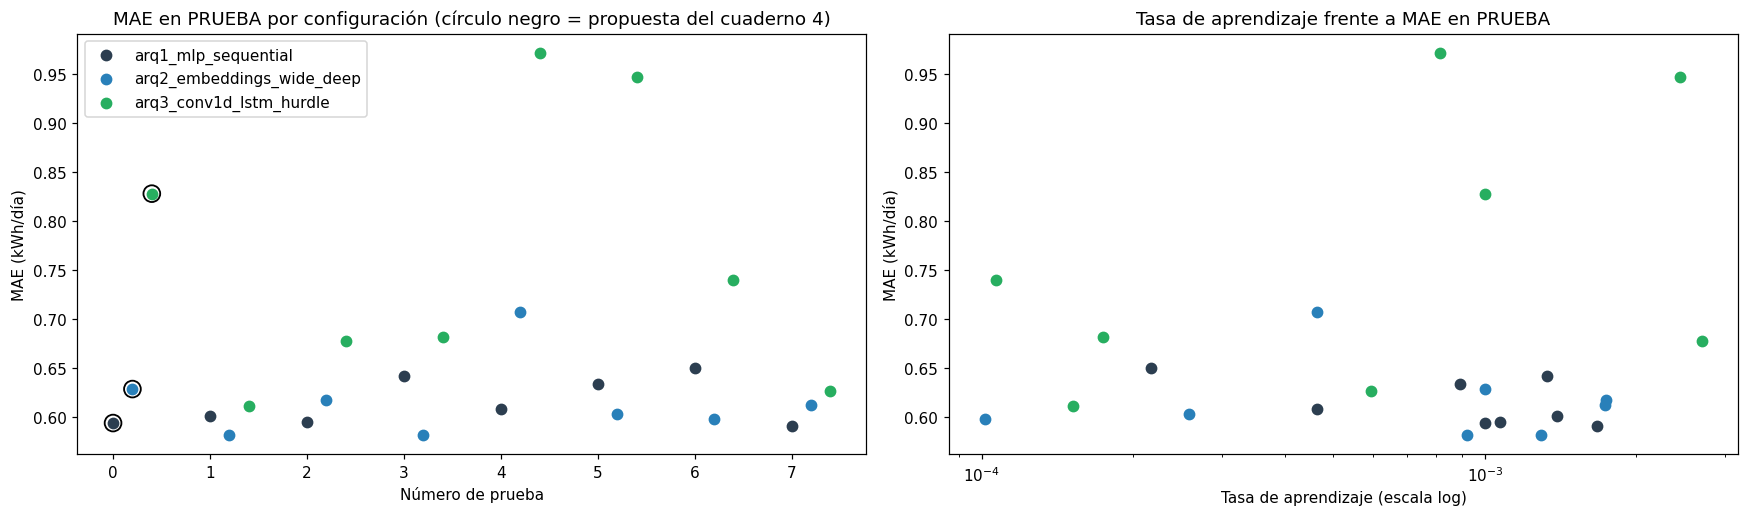

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(16, 4.8))
for j, nombre in enumerate(NOMBRES_MODELOS):
    sub = resultados_hp.loc[resultados_hp['Modelo'] == nombre]
    axes[0].scatter(sub['Prueba'] + j * 0.2, sub['MAE_PRUEBA'], color=PALETA[j], label=nombre, s=45)
    axes[0].scatter(0 + j * 0.2, sub.loc[sub['Prueba'] == 0, 'MAE_PRUEBA'], facecolors='none',
                    edgecolors='black', s=120, linewidths=1.2)
    axes[1].scatter(sub['tasa_aprendizaje'], sub['MAE_PRUEBA'], color=PALETA[j], label=nombre, s=45)
axes[0].set_title('MAE en PRUEBA por configuración (círculo negro = propuesta del cuaderno 4)')
axes[0].set_xlabel('Número de prueba')
axes[0].set_ylabel('MAE (kWh/día)')
axes[0].legend()
axes[1].set_xscale('log')
axes[1].set_title('Tasa de aprendizaje frente a MAE en PRUEBA')
axes[1].set_xlabel('Tasa de aprendizaje (escala log)')
axes[1].set_ylabel('MAE (kWh/día)')
plt.tight_layout()
guardar_figura(fig, '00_busqueda_hiperparametros')
plt.show()

## 8. Entrenamiento final con los mejores hiperparámetros

Para cada arquitectura:
1. Se reconstruye el modelo del cuaderno 4 (mismos pesos iniciales) con sus **mejores hiperparámetros** de la sección 7.
2. Se entrena con **toda** la muestra de ajuste y hasta `MAX_EPOCAS` épocas, con:
   - `EarlyStopping` (paciencia `PACIENCIA`) y `ReduceLROnPlateau` (factor 0,5) sobre la **MAE de kWh/día del subconjunto de monitoreo** (`val_mae`; `val_kwh_dia_mae` en la arquitectura 3). Se monitorea la misma métrica con la que se seleccionan los modelos y no la pérdida total, porque en la arquitectura 3 esta incluye la BCE de `prob_cero`, que puede empezar a sobreajustar mientras la MAE sigue mejorando,
   - `ModelCheckpoint` del **mejor** modelo (`checkpoints/<nombre>_mejor.keras`),
   - `ModelCheckpoint` del **último** estado, con el optimizador (`checkpoints/<nombre>_ultimo.keras`),
   - `CSVLogger` con la historia por época, incluida la duración (`historia_<nombre>.csv`).
3. El modelo final es el de la mejor época y se guarda en `Modelos_5_Entrenamiento/<nombre>_entrenado.keras`.

**Reanudación.** Si existe `<nombre>_entrenado.keras`, la red se omite. Si hay un entrenamiento a medias, se carga `_ultimo.keras` (pesos y estado de Adam, incluida la tasa de aprendizaje ya reducida) y se continúa con `initial_epoch` igual a las épocas registradas. Como Keras reinicia los contadores de `EarlyStopping` y `ReduceLROnPlateau` en cada `fit`, se restauran desde la historia guardada (mejor MAE de monitoreo y épocas sin mejora), y el *checkpoint* del mejor modelo recibe ese mismo umbral para no sobrescribirse con una época peor.

In [21]:
class TiempoEpoca(keras.callbacks.Callback):
    # Agrega la duración de cada época a los registros (queda en el CSV de historia)
    def on_epoch_begin(self, epoch, logs=None):
        self._inicio = time.time()

    def on_epoch_end(self, epoch, logs=None):
        if logs is not None:
            logs['segundos_epoca'] = time.time() - self._inicio


def estado_monitor(historia_previa, monitor):
    # (mejor valor, épocas transcurridas desde la mejor) según la historia guardada
    valores = historia_previa[monitor].to_numpy()
    return float(valores.min()), int(len(valores) - 1 - valores.argmin())


class EarlyStoppingReanudable(keras.callbacks.EarlyStopping):
    def __init__(self, historia_previa, **kwargs):
        super().__init__(**kwargs)
        self.historia_previa = historia_previa

    def on_train_begin(self, logs=None):
        super().on_train_begin(logs)
        if len(self.historia_previa):
            self.best, self.wait = estado_monitor(self.historia_previa, self.monitor)


class ReduceLROnPlateauReanudable(keras.callbacks.ReduceLROnPlateau):
    def __init__(self, historia_previa, **kwargs):
        super().__init__(**kwargs)
        self.historia_previa = historia_previa

    def on_train_begin(self, logs=None):
        super().on_train_begin(logs)
        if len(self.historia_previa):
            self.best, desde_mejor = estado_monitor(self.historia_previa, self.monitor)
            self.wait = desde_mejor % self.patience   # el contador vuelve a 0 tras cada reducción

In [22]:
historias, resumen_entrenamiento = {}, []

for nombre in NOMBRES_MODELOS:
    print(f'\n========== {nombre} ==========')
    hp = MEJORES_HP[nombre]
    ruta_ultimo = os.path.join(DIR_CHECKPOINTS, f'{nombre}_ultimo.keras')
    ruta_mejor = os.path.join(DIR_CHECKPOINTS, f'{nombre}_mejor.keras')
    ruta_hp = os.path.join(DIR_CHECKPOINTS, f'{nombre}_hiperparametros.json')
    ruta_hist = os.path.join(DIR_RESULTADOS, f'historia_{nombre}.csv')

    if os.path.exists(ruta_entrenado(nombre)) and not FORZAR_REINICIO:
        print('Entrenada en una sesión anterior: se omite.')
    else:
        reanudar = (not FORZAR_REINICIO) and all(os.path.exists(r) for r in (ruta_ultimo, ruta_mejor, ruta_hp, ruta_hist))
        if reanudar:
            with open(ruta_hp, encoding='utf-8') as fh:
                if json.load(fh) != hp:
                    raise ValueError(f'Los hiperparámetros de {nombre} cambiaron respecto al entrenamiento a medias. '
                                     'Use FORZAR_REINICIO = True para empezar de cero.')
            historia_previa = pd.read_csv(ruta_hist)
            modelo = keras.models.load_model(ruta_ultimo)
            print(f'Reanudando tras la época {len(historia_previa)} '
                  f'(tasa de aprendizaje {float(keras.ops.convert_to_numpy(modelo.optimizer.learning_rate)):.2e}).')
        else:
            for ruta in (ruta_ultimo, ruta_mejor, ruta_hist):
                if os.path.exists(ruta):
                    os.remove(ruta)
            with open(ruta_hp, 'w', encoding='utf-8') as fh:
                json.dump(hp, fh)
            historia_previa = pd.DataFrame()
            keras.utils.set_random_seed(SEMILLA)
            modelo = construir_variante(nombre, hp)
            print('Hiperparámetros:', hp)

        monitor = metrica_monitor(nombre)
        epoca_inicial = len(historia_previa)
        ya_detenido = epoca_inicial > 0 and estado_monitor(historia_previa, monitor)[1] >= PACIENCIA
        if epoca_inicial < MAX_EPOCAS and not ya_detenido:
            gen_ajuste = GeneradorLotes(nombre, T_train, idx_ajuste, hp['tamano_lote'], barajar=True)
            gen_monitor = GeneradorLotes(nombre, T_train, idx_monitor, TAMANO_LOTE_PRED, barajar=False)
            callbacks = [
                TiempoEpoca(),
                EarlyStoppingReanudable(historia_previa, monitor=monitor, mode='min', patience=PACIENCIA),
                ReduceLROnPlateauReanudable(historia_previa, monitor=monitor, mode='min', factor=0.5,
                                            patience=1, min_lr=1e-5),
                keras.callbacks.ModelCheckpoint(
                    ruta_mejor, monitor=monitor, mode='min', save_best_only=True,
                    initial_value_threshold=estado_monitor(historia_previa, monitor)[0] if epoca_inicial else None),
                keras.callbacks.ModelCheckpoint(ruta_ultimo, save_best_only=False),
                keras.callbacks.CSVLogger(ruta_hist, append=True),
            ]
            modelo.fit(gen_ajuste, validation_data=gen_monitor, initial_epoch=epoca_inicial,
                       epochs=MAX_EPOCAS, callbacks=callbacks, verbose=2)
            del gen_ajuste, gen_monitor

        # Modelo final = mejor época de monitoreo (incluye épocas de sesiones anteriores)
        modelo = keras.models.load_model(ruta_mejor)
        modelo.save(ruta_entrenado(nombre))
        del modelo
        keras.backend.clear_session()
        gc.collect()

    historias[nombre] = pd.read_csv(ruta_hist)
    h = historias[nombre]
    resumen_entrenamiento.append({
        'Modelo': nombre,
        **hp,
        'Parámetros': keras.models.load_model(ruta_entrenado(nombre)).count_params(),
        'Épocas ejecutadas': len(h),
        'Mejor época': int(h[metrica_monitor(nombre)].idxmin()) + 1,
        'Mejor MAE de monitoreo': h[metrica_monitor(nombre)].min(),
        'Minutos': h['segundos_epoca'].sum() / 60 if 'segundos_epoca' in h else np.nan,
    })

tabla_entrenamiento = pd.DataFrame(resumen_entrenamiento).set_index('Modelo')
guardar_tabla(tabla_entrenamiento, '02_resumen_entrenamiento')
tabla_entrenamiento


========== arq1_mlp_sequential ==========
Hiperparámetros: {'tasa_aprendizaje': 0.0016692123728804, 'tamano_lote': 2048, 'escala_dropout': 1.0, 'delta_huber': 0.5}
Epoch 1/20
35374/35374 - 188s - 5ms/step - loss: 0.2124 - mae: 0.6022 - rmse: 1.2446 - val_loss: 0.2411 - val_mae: 0.6715 - val_rmse: 1.3138 - segundos_epoca: 188.2613 - learning_rate: 0.0017
Epoch 2/20
35374/35374 - 178s - 5ms/step - loss: 0.2021 - mae: 0.5783 - rmse: 1.2048 - val_loss: 0.2673 - val_mae: 0.7291 - val_rmse: 1.4056 - segundos_epoca: 178.2568 - learning_rate: 0.0017
Epoch 3/20
35374/35374 - 165s - 5ms/step - loss: 0.1991 - mae: 0.5709 - rmse: 1.1952 - val_loss: 0.2638 - val_mae: 0.7223 - val_rmse: 1.4019 - segundos_epoca: 164.5290 - learning_rate: 8.3461e-04

========== arq2_embeddings_wide_deep ==========
Hiperparámetros: {'tasa_aprendizaje': 0.0012896989428089, 'tamano_lote': 4096, 'escala_dropout': 0.5, 'delta_huber': 0.5}
Epoch 1/20
17687/17687 - 155s - 9ms/step - loss: 0.2009 - mae: 0.5752 - rmse: 1.2088

,tasa_aprendizaje,tamano_lote,escala_dropout,delta_huber,Parámetros,Épocas ejecutadas,Mejor época,Mejor MAE de monitoreo,Minutos,peso_prob_cero
Modelo,,,,,,,,,,
arq1_mlp_sequential,0.0017,2048,1.0000,0.5000,68609,3,1,0.6715,8.8508,NaN
arq2_embeddings_wide_deep,0.0013,4096,0.5000,0.5000,303958,7,5,0.5749,15.8818,NaN
arq3_conv1d_lstm_hurdle,0.0002,8192,0.5000,1.0000,62298,3,1,0.6521,41.7296,0.3000


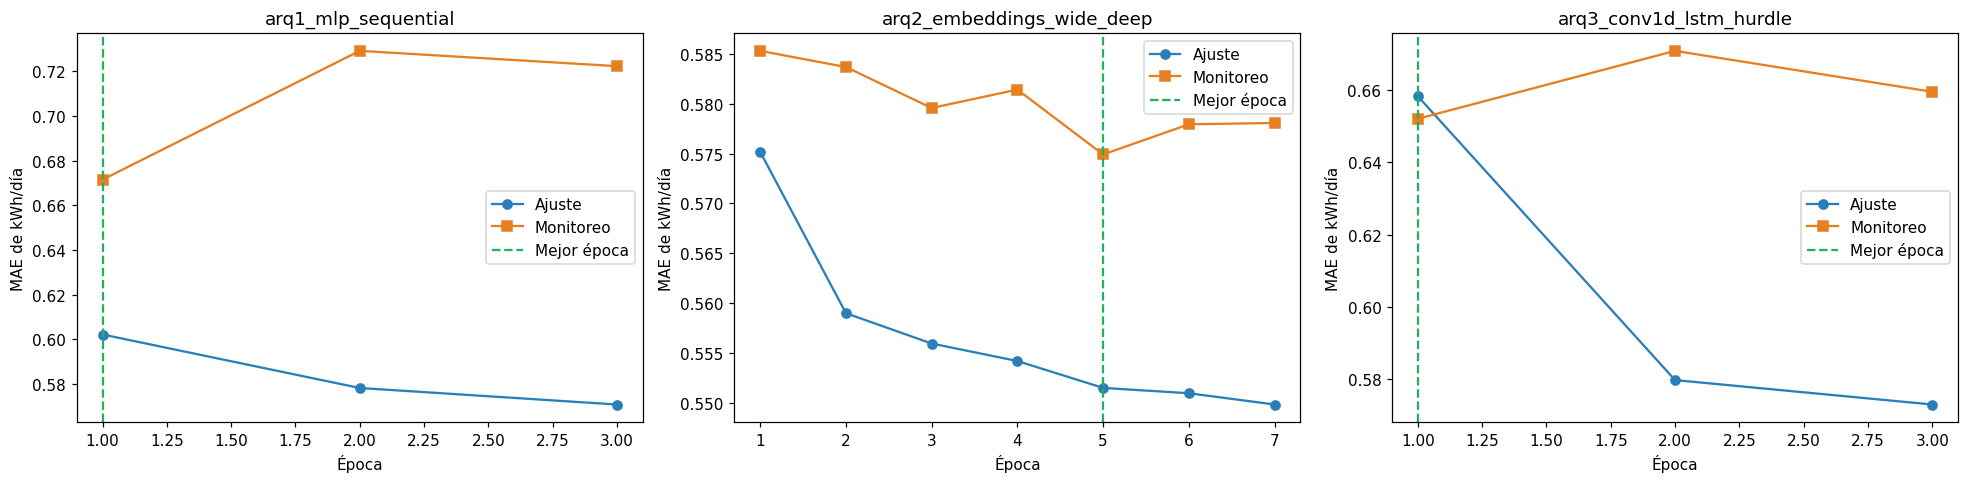

In [23]:
fig, axes = plt.subplots(1, len(NOMBRES_MODELOS), figsize=(6 * len(NOMBRES_MODELOS), 4.5))
for ax, nombre in zip(np.atleast_1d(axes), NOMBRES_MODELOS):
    h = historias[nombre]
    epocas = np.arange(1, len(h) + 1)
    monitor = metrica_monitor(nombre)
    ax.plot(epocas, h[monitor.removeprefix('val_')], marker='o', color=PALETA[1], label='Ajuste')
    ax.plot(epocas, h[monitor], marker='s', color=PALETA[3], label='Monitoreo')
    ax.axvline(h[monitor].idxmin() + 1, color=PALETA[2], linestyle='--', label='Mejor época')
    ax.set_title(nombre)
    ax.set_xlabel('Época')
    ax.set_ylabel('MAE de kWh/día')
    ax.legend()
plt.tight_layout()
guardar_figura(fig, '01_curvas_aprendizaje')
plt.show()

In [24]:
# Liberar la memoria del entrenamiento
T_train = None
_ = gc.collect()

## 9. Comparación de los modelos en PRUEBA (15 %)

Se evalúan las tres arquitecturas ya optimizadas y entrenadas y, como referencia, la línea base semestral, sobre el 100 % de PRUEBA, en cuatro subconjuntos:
- **Todos los registros** de PRUEBA (la población sobre la que se aplicaría el modelo).
- **Subconjunto comparable con la línea base:** `BENCH_VALIDO == 1`, `KWH_DIA ≤ 100` y `BENCH_KWH_DIA ≤ 100` (documento, Tabla 3.3).
- **Registros con consumo real cero** y **con consumo positivo**, para ver dónde gana o pierde cada modelo (la banda de ceros es una de las motivaciones de la arquitectura 3).

El modelo se selecciona con el menor `CRITERIO_SELECCION` sobre **todos los registros** de PRUEBA.

> Como PRUEBA se usó para elegir hiperparámetros, arquitectura y umbral, sus métricas del modelo ganador son optimistas. La estimación no sesgada del desempeño es la de VALIDACIÓN (sección 10).

In [25]:
pred_prueba, prob_cero_prueba = {}, {}
for nombre in NOMBRES_MODELOS:
    pred_prueba[nombre], prob_cero_prueba[nombre] = predecir_con_cache(nombre, T_prueba, 'PRUEBA')

arq1_mlp_sequential (PRUEBA): predicción en 0.2 min
arq2_embeddings_wide_deep (PRUEBA): predicción en 0.2 min
arq3_conv1d_lstm_hurdle (PRUEBA): predicción en 3.0 min


### 9.1 Regla de umbral sobre `prob_cero` (arquitectura 3)

La salida `kwh_dia` de la arquitectura 3 **ya es** el valor esperado `(1 − p)·μ⁺`: la red multiplica internamente la probabilidad de consumo por la magnitud (capas `prob_consumo` y `kwh_dia`, cuaderno 4). Volver a multiplicar por `(1 − p)` contaría dos veces la probabilidad de cero.

Lo que sí puede mejorar la MAE es una **regla de decisión**: con pérdida absoluta, la mejor predicción puntual es la **mediana** de la distribución del consumo, y cuando `P(consumo = 0) ≥ 0,5` esa mediana es 0. Por eso se evalúa en PRUEBA la regla «predecir 0 si `prob_cero ≥ τ`» con τ ∈ `UMBRALES_PROB_CERO` (todos ≥ 0,5). Si el mejor τ reduce la MAE frente a la salida sin umbral, la variante `arq3…+umbral_cero` entra a la comparación como un candidato más; si no, se descarta.

In [26]:
NOMBRE_ARQ3 = 'arq3_conv1d_lstm_hurdle'
UMBRAL_CERO_ELEGIDO = None
p_cero = prob_cero_prueba.get(NOMBRE_ARQ3)

if p_cero is not None:
    base = pred_prueba[NOMBRE_ARQ3]
    es_cero = T_prueba['y'] == 0
    filas_umbral = [{'Umbral': 'sin umbral', '% predicho como 0': 0.0,
                     'MAE todos': metricas_regresion(T_prueba['y'], base)['MAE'],
                     'MAE consumo cero': metricas_regresion(T_prueba['y'][es_cero], base[es_cero])['MAE'],
                     'MAE consumo > 0': metricas_regresion(T_prueba['y'][~es_cero], base[~es_cero])['MAE']}]
    for tau in UMBRALES_PROB_CERO:
        y_u = np.where(p_cero >= tau, 0.0, base)
        filas_umbral.append({'Umbral': tau, '% predicho como 0': (p_cero >= tau).mean() * 100,
                             'MAE todos': metricas_regresion(T_prueba['y'], y_u)['MAE'],
                             'MAE consumo cero': metricas_regresion(T_prueba['y'][es_cero], y_u[es_cero])['MAE'],
                             'MAE consumo > 0': metricas_regresion(T_prueba['y'][~es_cero], y_u[~es_cero])['MAE']})
    tabla_umbral = pd.DataFrame(filas_umbral).set_index('Umbral')
    guardar_tabla(tabla_umbral, '11_umbral_prob_cero_prueba')
    display(tabla_umbral)

    con_umbral = tabla_umbral.drop(index='sin umbral')
    mejor_tau = con_umbral['MAE todos'].idxmin()
    if con_umbral.loc[mejor_tau, 'MAE todos'] < tabla_umbral.loc['sin umbral', 'MAE todos']:
        UMBRAL_CERO_ELEGIDO = float(mejor_tau)
        pred_prueba[NOMBRE_ARQ3 + SUFIJO_UMBRAL] = np.where(p_cero >= UMBRAL_CERO_ELEGIDO, 0.0, base).astype('float32')
        print(f'El umbral {UMBRAL_CERO_ELEGIDO} reduce la MAE: la variante entra a la comparación.')
    else:
        print('Ningún umbral reduce la MAE en PRUEBA: se mantiene la salida kwh_dia sin umbral.')

,% predicho como 0,MAE todos,MAE consumo cero,MAE consumo > 0
Umbral,,,,
sin umbral,0.0000,0.6551,0.4209,0.6628
0.5000,3.1790,0.6538,0.3674,0.6632
0.6000,2.5891,0.6542,0.3845,0.6630
0.7000,1.9620,0.6545,0.3985,0.6629
0.8000,1.2529,0.6548,0.4097,0.6628
0.9000,0.1910,0.6551,0.4198,0.6628


El umbral 0.5 reduce la MAE: la variante entra a la comparación.


In [27]:
pred_prueba['LINEA_BASE'] = T_prueba['bench']

mask_comp_prueba = mascara_comparable(T_prueba)
es_cero_prueba = T_prueba['y'] == 0
filas = []
for subconjunto, mascara in [('Todos los registros', np.ones_like(mask_comp_prueba)),
                             ('Comparable con la línea base', mask_comp_prueba),
                             ('Consumo real cero', es_cero_prueba),
                             ('Consumo real > 0', ~es_cero_prueba)]:
    for nombre, y_hat in pred_prueba.items():
        filas.append({'Subconjunto': subconjunto, 'Modelo': nombre,
                      **metricas_regresion(T_prueba['y'][mascara], y_hat[mascara])})

tabla_prueba = pd.DataFrame(filas).set_index(['Subconjunto', 'Modelo'])
guardar_tabla(tabla_prueba, '03_comparacion_modelos_prueba')
tabla_prueba

n  \
Subconjunto                  Modelo                                          
Todos los registros          arq1_mlp_sequential                  16363756   
                             arq2_embeddings_wide_deep            16363756   
                             arq3_conv1d_lstm_hurdle              16363756   
                             arq3_conv1d_lstm_hurdle+umbral_cero  16363756   
                             LINEA_BASE                           16363756   
Comparable con la línea base arq1_mlp_sequential                  16024427   
                             arq2_embeddings_wide_deep            16024427   
                             arq3_conv1d_lstm_hurdle              16024427   
                             arq3_conv1d_lstm_hurdle+umbral_cero  16024427   
                             LINEA_BASE                           16024427   
Consumo real cero            arq1_mlp_sequential                    519074   
                             arq2_embeddings_wide_deep              519074   
                             arq3_conv1d_lstm_hurdle                519074   
                             arq3_conv1d_lstm_hurdle+umbral_cero    519074   
                             LINEA_BASE                             519074   
Consumo real > 0             arq1_mlp_sequential                  15844682   
                             arq2_embeddings_wide_deep            15844682   
                             arq3_conv1d_lstm_hurdle              15844682   
                             arq3_conv1d_lstm_hurdle+umbral_cero  15844682   
                             LINEA_BASE                           15844682   

                                                                    MAE  \
Subconjunto                  Modelo                                       
Todos los registros          arq1_mlp_sequential                 0.6753   
                             arq2_embeddings_wide_deep           0.5779   
                             arq3_conv1d_lstm_hurdle             0.6551   
                             arq3_conv1d_lstm_hurdle+umbral_cero 0.6538   
                             LINEA_BASE                          0.7652   
Comparable con la línea base arq1_mlp_sequential                 0.6763   
                             arq2_embeddings_wide_deep           0.5791   
                             arq3_conv1d_lstm_hurdle             0.6563   
                             arq3_conv1d_lstm_hurdle+umbral_cero 0.6550   
                             LINEA_BASE                          0.6526   
Consumo real cero            arq1_mlp_sequential                 0.5491   
                             arq2_embeddings_wide_deep           0.4250   
                             arq3_conv1d_lstm_hurdle             0.4209   
                             arq3_conv1d_lstm_hurdle+umbral_cero 0.3674   
                             LINEA_BASE                          0.8507   
Consumo real > 0             arq1_mlp_sequential                 0.6794   
                             arq2_embeddings_wide_deep           0.5829   
                             arq3_conv1d_lstm_hurdle             0.6628   
                             arq3_conv1d_lstm_hurdle+umbral_cero 0.6632   
                             LINEA_BASE                          0.7624   

                                                                    RMSE  \
Subconjunto                  Modelo                                        
Todos los registros          arq1_mlp_sequential                  1.3301   
                             arq2_embeddings_wide_deep            1.2058   
                             arq3_conv1d_lstm_hurdle              1.2915   
                             arq3_conv1d_lstm_hurdle+umbral_cero  1.2921   
                             LINEA_BASE                           4.1239   
Comparable con la línea base arq1_mlp_sequential                  1.3318   
                             arq2_embeddings_wide_deep            1.2071   
                     

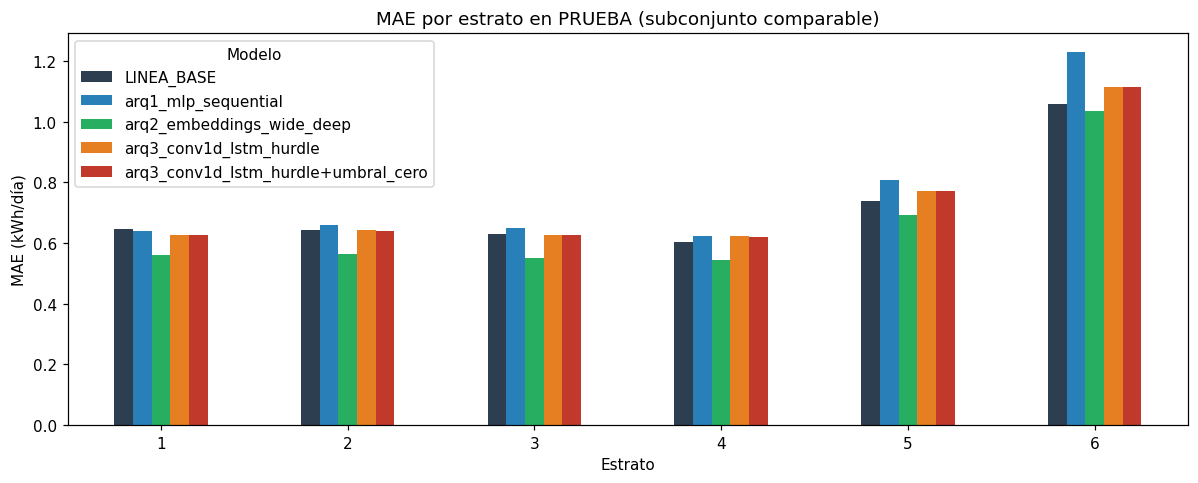

Modelo,LINEA_BASE,arq1_mlp_sequential,arq2_embeddings_wide_deep,arq3_conv1d_lstm_hurdle,arq3_conv1d_lstm_hurdle+umbral_cero
Estrato,,,,,
1,0.6473,0.6385,0.5618,0.6279,0.6267
2,0.6438,0.6602,0.5636,0.6423,0.6413
3,0.6297,0.6483,0.5506,0.6280,0.6265
4,0.6037,0.6229,0.5447,0.6220,0.6206
5,0.7398,0.8073,0.6916,0.7724,0.7713
6,1.0575,1.2302,1.0353,1.1141,1.1129


In [28]:
# MAE por estrato en el subconjunto comparable
filas_estrato = []
for estrato in range(1, 7):
    m = mask_comp_prueba & (T_prueba['estrato'] == estrato)
    for nombre, y_hat in pred_prueba.items():
        filas_estrato.append({'Estrato': estrato, 'Modelo': nombre,
                              'MAE': metricas_regresion(T_prueba['y'][m], y_hat[m])['MAE']})
mae_estrato_prueba = pd.DataFrame(filas_estrato).pivot(index='Estrato', columns='Modelo', values='MAE')
guardar_tabla(mae_estrato_prueba, '04_mae_por_estrato_prueba')

fig, ax = plt.subplots(figsize=(11, 4.5))
mae_estrato_prueba.plot(kind='bar', ax=ax, color=PALETA[:mae_estrato_prueba.shape[1]], rot=0)
ax.set_title('MAE por estrato en PRUEBA (subconjunto comparable)')
ax.set_ylabel('MAE (kWh/día)')
plt.tight_layout()
guardar_figura(fig, '02_mae_por_estrato_prueba')
plt.show()
mae_estrato_prueba

In [29]:
# Arquitectura 3: calidad de la salida auxiliar de probabilidad de consumo cero
p = prob_cero_prueba.get('arq3_conv1d_lstm_hurdle')
if p is not None:
    es_cero = T_prueba['y'] == 0
    display(pd.Series({
        '% ceros reales': es_cero.mean() * 100,
        'Probabilidad media predicha (%)': p.mean() * 100,
        'AUC (ceros vs. no ceros)': auc_roc(es_cero, p),
    }, name='arq3 · prob_cero (PRUEBA)').to_frame())

# Selección del modelo
tabla_sel = tabla_prueba.loc['Todos los registros'].drop(index='LINEA_BASE')
MODELO_SELECCIONADO = tabla_sel[CRITERIO_SELECCION].idxmin()
print(f'Modelo seleccionado en PRUEBA por menor {CRITERIO_SELECCION}: {MODELO_SELECCIONADO}')
tabla_sel.sort_values(CRITERIO_SELECCION)

,arq3 · prob_cero (PRUEBA)
% ceros reales,3.1721
Probabilidad media predicha (%),3.3825
AUC (ceros vs. no ceros),0.9751


Modelo seleccionado en PRUEBA por menor MAE: arq2_embeddings_wide_deep


,n,MAE,RMSE,R2,Sesgo
Modelo,,,,,
arq2_embeddings_wide_deep,16363756,0.5779,1.2058,0.8992,-0.1217
arq3_conv1d_lstm_hurdle+umbral_cero,16363756,0.6538,1.2921,0.8842,-0.3257
arq3_conv1d_lstm_hurdle,16363756,0.6551,1.2915,0.8843,-0.3230
arq1_mlp_sequential,16363756,0.6753,1.3301,0.8773,-0.1996


In [30]:
del T_prueba, pred_prueba, prob_cero_prueba
_ = gc.collect()

## 10. Validación del modelo seleccionado frente a la línea base (15 %)

VALIDACIÓN se abre una sola vez, con el modelo ya elegido en PRUEBA. Se reporta:
1. MAE, RMSE, R² y sesgo del modelo y de la línea base (todos los registros y subconjunto comparable).
2. Métricas por año y por estrato.
3. **Diferencia de MAE por usuario** (línea base − modelo; positivo = el modelo mejora), con intervalo de confianza del 95 % por *bootstrap* sobre usuarios. Cada usuario pesa igual, lo que respeta la independencia entre usuarios.

In [31]:
asegurar_bloques(['VALIDACION'])   # ya listos si se crearon junto con PRUEBA en esta sesión
T_valid = transformar_en_sitio(
    construir_crudo('VALIDACION', prep['vocabularios'], guardar_meta=GUARDAR_PREDICCIONES_VALID), prep)
_ = gc.collect()

nombre_red = MODELO_SELECCIONADO.removesuffix(SUFIJO_UMBRAL)
y_hat_valid, p_cero_valid = predecir_con_cache(nombre_red, T_valid, 'VALIDACION')
if MODELO_SELECCIONADO.endswith(SUFIJO_UMBRAL):
    # Se aplica el umbral elegido en PRUEBA, sin reajustarlo en VALIDACIÓN
    y_hat_valid = np.where(p_cero_valid >= UMBRAL_CERO_ELEGIDO, 0.0, y_hat_valid).astype('float32')
    print(f'Regla de umbral aplicada: predecir 0 si prob_cero >= {UMBRAL_CERO_ELEGIDO}')
mask_comp_valid = mascara_comparable(T_valid)

pred_valid = {MODELO_SELECCIONADO: y_hat_valid, 'LINEA_BASE': T_valid['bench']}
filas = []
es_cero_valid = T_valid['y'] == 0
for subconjunto, mascara in [('Todos los registros', np.ones_like(mask_comp_valid)),
                             ('Comparable con la línea base', mask_comp_valid),
                             ('Consumo real cero', es_cero_valid),
                             ('Consumo real > 0', ~es_cero_valid)]:
    for nombre, y_hat in pred_valid.items():
        filas.append({'Subconjunto': subconjunto, 'Modelo': nombre,
                      **metricas_regresion(T_valid['y'][mascara], y_hat[mascara])})
tabla_valid = pd.DataFrame(filas).set_index(['Subconjunto', 'Modelo'])

comp = tabla_valid.loc['Comparable con la línea base']
reduccion_mae = (1 - comp.loc[MODELO_SELECCIONADO, 'MAE'] / comp.loc['LINEA_BASE', 'MAE']) * 100
reduccion_rmse = (1 - comp.loc[MODELO_SELECCIONADO, 'RMSE'] / comp.loc['LINEA_BASE', 'RMSE']) * 100
print(f'Reducción frente a la línea base (subconjunto comparable): MAE {reduccion_mae:.2f} % | RMSE {reduccion_rmse:.2f} %')
guardar_tabla(tabla_valid, '05_validacion_modelo_vs_linea_base')
tabla_valid

VALIDACION_00: 8,210,154 registros | hex [55706, 60621)
   % con transformador en catálogo: 100.00 | % con circuito en catálogo: 99.96 | % meses observados (solo panel): 85.57 | % coincidencia panel = KWH_DIA_LAG1: 100.00 | % coincidencia panel = KWH_DIA_LAG3: 100.00 | % coincidencia panel = KWH_DIA_LAG12: 100.00 | % meses observados (panel + rezagos): 85.62
VALIDACION_01: 8,178,693 registros | hex [60621, 65536)
   % con transformador en catálogo: 100.00 | % con circuito en catálogo: 99.96 | % meses observados (solo panel): 85.56 | % coincidencia panel = KWH_DIA_LAG1: 100.00 | % coincidencia panel = KWH_DIA_LAG3: 100.00 | % coincidencia panel = KWH_DIA_LAG12: 100.00 | % meses observados (panel + rezagos): 85.61
VALIDACION: 16,388,847 registros | 362,187 usuarios | 3.19 GB | 3.4 min
arq2_embeddings_wide_deep (VALIDACION): predicción en 0.2 min
Reducción frente a la línea base (subconjunto comparable): MAE 11.26 % | RMSE 12.14 %


n    MAE  \
Subconjunto                  Modelo                                       
Todos los registros          arq2_embeddings_wide_deep  16388847 0.5765   
                             LINEA_BASE                 16388847 0.8043   
Comparable con la línea base arq2_embeddings_wide_deep  16048529 0.5777   
                             LINEA_BASE                 16048529 0.6510   
Consumo real cero            arq2_embeddings_wide_deep    519948 0.4258   
                             LINEA_BASE                   519948 2.0048   
Consumo real > 0             arq2_embeddings_wide_deep  15868899 0.5814   
                             LINEA_BASE                 15868899 0.7649   

                                                           RMSE          R2  \
Subconjunto                  Modelo                                           
Todos los registros          arq2_embeddings_wide_deep   1.2018      0.8992   
                             LINEA_BASE                143.3601 -1,432.7708   
Comparable con la línea base arq2_embeddings_wide_deep   1.2035      0.8989   
                             LINEA_BASE                  1.3698      0.8691   
Consumo real cero            arq2_embeddings_wide_deep   1.2358         NaN   
                             LINEA_BASE                804.1731         NaN   
Consumo real > 0             arq2_embeddings_wide_deep   1.2007      0.8983   
                             LINEA_BASE                  6.0366     -1.5711   

                                                         Sesgo  
Subconjunto                  Modelo                             
Todos los registros          arq2_embeddings_wide_deep -0.1209  
                             LINEA_BASE                -0.0028  
Comparable con la línea base arq2_embeddings_wide_deep -0.1213  
                             LINEA_BASE                 0.0115  
Consumo real cero            arq2_embeddings_wide_deep  0.2304  
                             LINEA_BASE                 2.0048  
Consumo real > 0             arq2_embeddings_wide_deep -0.1324  
                             LINEA_BASE                -0.0686

In [32]:
# Métricas por año y por estrato (subconjunto comparable)
def metricas_por_grupo(grupo, etiqueta):
    filas = []
    for valor in np.unique(grupo[mask_comp_valid]):
        m = mask_comp_valid & (grupo == valor)
        for nombre, y_hat in pred_valid.items():
            r = metricas_regresion(T_valid['y'][m], y_hat[m])
            filas.append({etiqueta: valor, 'Modelo': nombre, 'n': r['n'], 'MAE': r['MAE'], 'RMSE': r['RMSE'], 'R2': r['R2']})
    return pd.DataFrame(filas).pivot(index=etiqueta, columns='Modelo', values=['MAE', 'RMSE', 'R2'])

valid_por_anio = metricas_por_grupo(T_valid['anio'], 'Año')
valid_por_estrato = metricas_por_grupo(T_valid['estrato'], 'Estrato')
guardar_tabla(valid_por_anio, '06_validacion_por_anio')
guardar_tabla(valid_por_estrato, '07_validacion_por_estrato')
display(valid_por_anio)
display(valid_por_estrato)

MAE                                 RMSE  \
Modelo LINEA_BASE arq2_embeddings_wide_deep LINEA_BASE   
Año                                                      
2022       0.7679                    0.7108     1.4401   
2023       0.5416                    0.5493     1.2028   
2024       0.5882                    0.5296     1.3049   
2025       0.6976                    0.5241     1.4950   

                                         R2                            
Modelo arq2_embeddings_wide_deep LINEA_BASE arq2_embeddings_wide_deep  
Año                                                                    
2022                      1.5107     0.8607                    0.8467  
2023                      1.0941     0.8997                    0.9170  
2024                      1.0808     0.8770                    0.9156  
2025                      1.0755     0.8423                    0.9184

MAE                                 RMSE  \
Modelo  LINEA_BASE arq2_embeddings_wide_deep LINEA_BASE   
Estrato                                                   
1           0.6483                    0.5627     1.2400   
2           0.6424                    0.5621     1.2547   
3           0.6281                    0.5495     1.4310   
4           0.6039                    0.5458     1.2532   
5           0.7301                    0.6838     1.5026   
6           1.0478                    1.0234     2.1149   

                                          R2                            
Modelo  arq2_embeddings_wide_deep LINEA_BASE arq2_embeddings_wide_deep  
Estrato                                                                 
1                          1.1070     0.8584                    0.8872  
2                          1.1310     0.8789                    0.9016  
3                          1.1701     0.8514                    0.9007  
4                          1.1509     0.8665                    0.8874  
5                          1.4136     0.8823                    0.8958  
6                          2.0195     0.8783                    0.8891

In [33]:
# Diferencia de MAE por usuario con bootstrap (subconjunto comparable)
def bootstrap_por_usuario(usuario, err_modelo, err_base, n_boot, semilla):
    _, inv = np.unique(usuario, return_inverse=True)
    n_reg = np.bincount(inv)
    mae_modelo = np.bincount(inv, weights=np.abs(err_modelo)) / n_reg
    mae_base = np.bincount(inv, weights=np.abs(err_base)) / n_reg
    diferencia = mae_base - mae_modelo
    rng = np.random.default_rng(semilla)
    medias = np.empty(n_boot)
    for b in range(n_boot):
        medias[b] = diferencia[rng.integers(0, len(diferencia), size=len(diferencia))].mean()
    ic_inf, ic_sup = np.percentile(medias, [2.5, 97.5])
    return {
        'Usuarios': len(diferencia),
        'MAE medio por usuario · modelo': mae_modelo.mean(),
        'MAE medio por usuario · línea base': mae_base.mean(),
        'Diferencia media (base − modelo)': diferencia.mean(),
        'IC95 inferior': ic_inf,
        'IC95 superior': ic_sup,
        '% usuarios con menor error del modelo': (diferencia > 0).mean() * 100,
    }

m = mask_comp_valid
resultado_bootstrap = bootstrap_por_usuario(
    T_valid['usuario'][m],
    y_hat_valid[m] - T_valid['y'][m],
    T_valid['bench'][m] - T_valid['y'][m],
    N_BOOTSTRAP, SEMILLA,
)
tabla_bootstrap = pd.Series(resultado_bootstrap, name=MODELO_SELECCIONADO).to_frame()
guardar_tabla(tabla_bootstrap, '08_bootstrap_usuarios_validacion')
tabla_bootstrap

,arq2_embeddings_wide_deep
Usuarios,"362,168.0000"
MAE medio por usuario · modelo,0.6070
MAE medio por usuario · línea base,0.6821
Diferencia media (base − modelo),0.0751
IC95 inferior,0.0723
IC95 superior,0.0778
% usuarios con menor error del modelo,67.6366


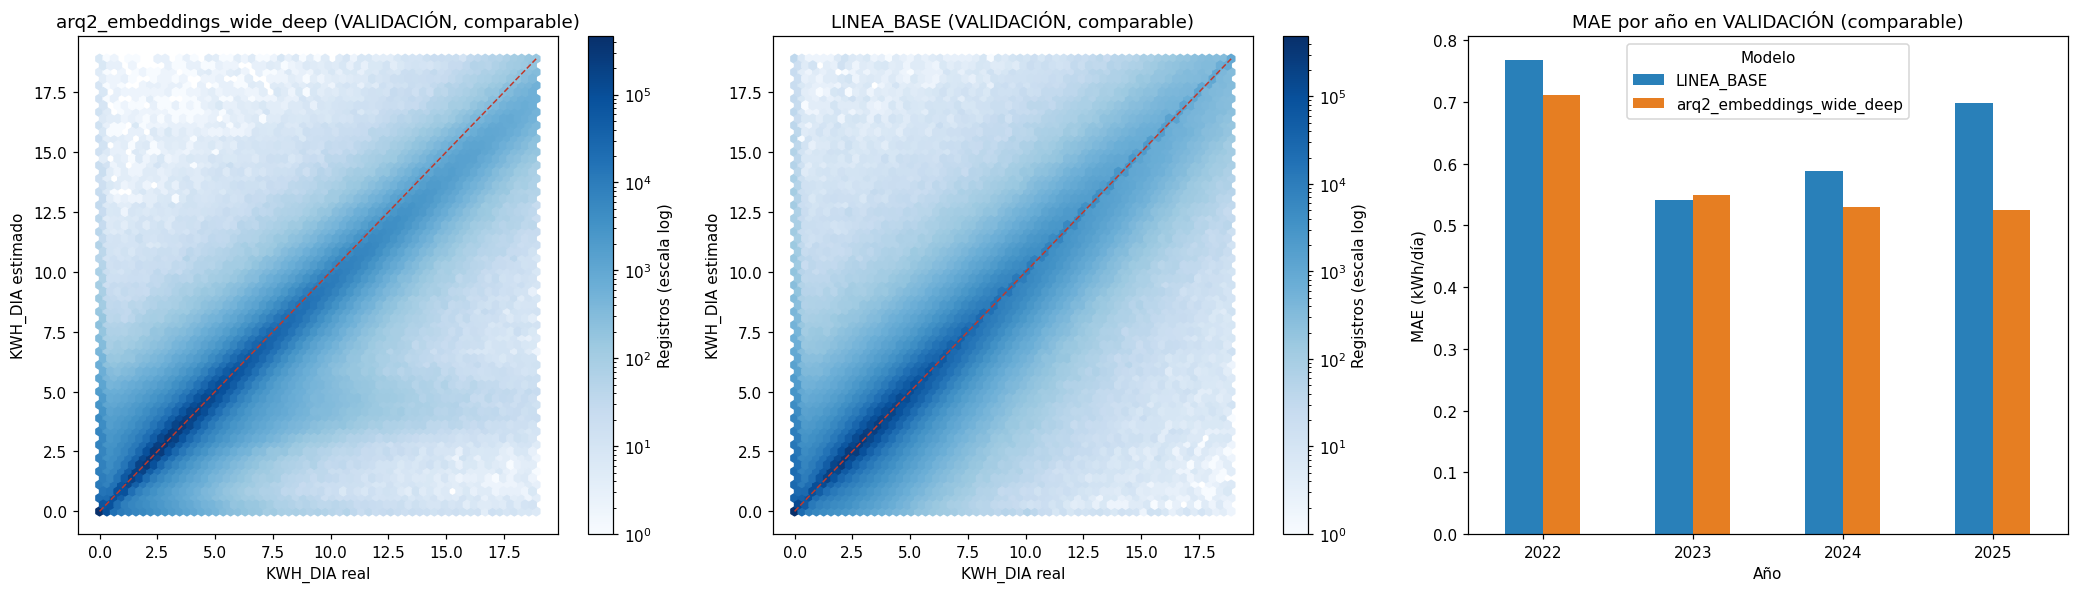

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))
lim = float(np.percentile(T_valid['y'][mask_comp_valid], 99))

for ax, (nombre, y_hat) in zip(axes[:2], pred_valid.items()):
    m = mask_comp_valid & np.isfinite(y_hat)
    hb = ax.hexbin(T_valid['y'][m], y_hat[m], gridsize=60, extent=(0, lim, 0, lim), bins='log', cmap='Blues', mincnt=1)
    ax.plot([0, lim], [0, lim], color=PALETA[4], linestyle='--', linewidth=1)
    ax.set_title(f'{nombre} (VALIDACIÓN, comparable)')
    ax.set_xlabel('KWH_DIA real')
    ax.set_ylabel('KWH_DIA estimado')
    fig.colorbar(hb, ax=ax, label='Registros (escala log)')

mae_anio = valid_por_anio['MAE']
mae_anio.plot(kind='bar', ax=axes[2], color=[PALETA[1], PALETA[3]], rot=0)
axes[2].set_title('MAE por año en VALIDACIÓN (comparable)')
axes[2].set_ylabel('MAE (kWh/día)')
plt.tight_layout()
guardar_figura(fig, '03_validacion_modelo_vs_linea_base')
plt.show()

## 11. Resumen y exportación

In [35]:
if GUARDAR_PREDICCIONES_VALID:
    predicciones = T_valid['meta'].assign(
        KWH_DIA=T_valid['y'], KWH_DIA_ESTIMADO=y_hat_valid, BENCH_KWH_DIA=T_valid['bench'],
        COMPARABLE=mask_comp_valid.astype('int8'),
    )
    if p_cero_valid is not None:
        predicciones['PROB_CERO'] = p_cero_valid
    predicciones.to_parquet(os.path.join(DIR_RESULTADOS, f'predicciones_validacion_{MODELO_SELECCIONADO}.parquet'), index=False)

resumen = {
    'modelo_seleccionado': MODELO_SELECCIONADO,
    'criterio_seleccion': f'{CRITERIO_SELECCION} mínimo en PRUEBA (todos los registros)',
    'fraccion_usuarios_entrenamiento': FRAC_USUARIOS_TRAIN,
    'mejores_hiperparametros': MEJORES_HP,
    'umbral_prob_cero': UMBRAL_CERO_ELEGIDO,
    'busqueda_hiperparametros': {'metodo': 'aleatoria', 'pruebas_por_arquitectura': N_PRUEBAS_HP,
                                 'puntuacion': 'MAE en PRUEBA', 'espacio': ESPACIO_HP},
    'validacion_comparable': {
        'modelo': comp.loc[MODELO_SELECCIONADO].to_dict(),
        'linea_base': comp.loc['LINEA_BASE'].to_dict(),
        'reduccion_mae_pct': reduccion_mae,
        'reduccion_rmse_pct': reduccion_rmse,
    },
    'bootstrap_usuarios': resultado_bootstrap,
}
with open(os.path.join(DIR_RESULTADOS, 'resumen_entrenamiento.json'), 'w', encoding='utf-8') as fh:
    json.dump(resumen, fh, ensure_ascii=False, indent=2, default=float)

supera = resultado_bootstrap['IC95 inferior'] > 0
print(f"Modelo seleccionado: {MODELO_SELECCIONADO}")
print(f"VALIDACIÓN (comparable): MAE {comp.loc[MODELO_SELECCIONADO, 'MAE']:.4f} vs. {comp.loc['LINEA_BASE', 'MAE']:.4f} kWh/día "
      f"| RMSE {comp.loc[MODELO_SELECCIONADO, 'RMSE']:.4f} vs. {comp.loc['LINEA_BASE', 'RMSE']:.4f} "
      f"| R² {comp.loc[MODELO_SELECCIONADO, 'R2']:.4f} vs. {comp.loc['LINEA_BASE', 'R2']:.4f}")
print(f"Diferencia media de MAE por usuario (base − modelo): {resultado_bootstrap['Diferencia media (base − modelo)']:.4f} "
      f"kWh/día, IC95 [{resultado_bootstrap['IC95 inferior']:.4f}, {resultado_bootstrap['IC95 superior']:.4f}]")
print('Conclusión:', 'el modelo SUPERA a la línea base (IC95 por encima de 0).' if supera
      else 'no hay evidencia de que el modelo supere a la línea base (el IC95 incluye o queda bajo 0).')
print('\nArchivos en Drive:')
for directorio in (DIR_MODELOS_ENT, DIR_RESULTADOS, DIR_FIGURAS):
    for archivo in sorted(os.listdir(directorio)):
        print(f' - {os.path.relpath(os.path.join(directorio, archivo), DRIVE_RAIZ)}')

Modelo seleccionado: arq2_embeddings_wide_deep
VALIDACIÓN (comparable): MAE 0.5777 vs. 0.6510 kWh/día | RMSE 1.2035 vs. 1.3698 | R² 0.8989 vs. 0.8691
Diferencia media de MAE por usuario (base − modelo): 0.0751 kWh/día, IC95 [0.0723, 0.0778]
Conclusión: el modelo SUPERA a la línea base (IC95 por encima de 0).

Archivos en Drive:
 - V2/Modelos_5_Entrenamiento/arq1_mlp_sequential_entrenado.keras
 - V2/Modelos_5_Entrenamiento/arq2_embeddings_wide_deep_entrenado.keras
 - V2/Modelos_5_Entrenamiento/arq3_conv1d_lstm_hurdle_entrenado.keras
 - V2/Modelos_5_Entrenamiento/checkpoints
 - V2/Modelos_5_Entrenamiento/mejores_hiperparametros.json
 - V2/Modelos_5_Entrenamiento/preprocesamiento.json
 - V2/Resultados_5_Entrenamiento_Modelos/00_resumen_particion.csv
 - V2/Resultados_5_Entrenamiento_Modelos/01_descriptivas_y_transformaciones.csv
 - V2/Resultados_5_Entrenamiento_Modelos/02_resumen_entrenamiento.csv
 - V2/Resultados_5_Entrenamiento_Modelos/03_comparacion_modelos_prueba.csv
 - V2/Resultados_5

### Conclusiones

*(Completar tras la ejecución con los valores de las tablas `03` a `11` de `Resultados_5_Entrenamiento_Modelos`.)*

1. **Optimización de hiperparámetros:** mejora de cada arquitectura frente a su configuración propuesta (tabla `10`) e hiperparámetros con mayor efecto.
2. **Redes neuronales frente a LightGBM:** se completa con la sección de comparación de `6_Modelo_LightGBM.ipynb`.
3. **Comparación en PRUEBA:** modelo seleccionado y diferencia frente a los demás, incluida la regla de umbral de la arquitectura 3 (tabla `11`) y el desempeño en meses con consumo cero.
4. **Validación frente a la línea base:** MAE, RMSE y R² en el subconjunto comparable; reducción porcentual e intervalo de confianza por usuario.
5. **Estabilidad:** comportamiento por año y por estrato.
6. **Limitaciones:** fracción de usuarios usada en el entrenamiento (`FRAC_USUARIOS_TRAIN`), presupuesto de la búsqueda (`N_PRUEBAS_HP`), la partición por usuario (no temporal) y la secuencia de la arquitectura 3, que solo tiene rezagos de BigQuery en t−1, t−3 y t−12.

### Referencias

- Bergstra, J. y Bengio, Y. (2012). Random Search for Hyper-Parameter Optimization. *Journal of Machine Learning Research*, 13, 281–305.
- Huber, P. J. (1964). Robust Estimation of a Location Parameter. *Annals of Mathematical Statistics*, 35(1).
- Efron, B. y Tibshirani, R. J. (1993). *An Introduction to the Bootstrap*. Chapman & Hall.